# Tabular foundation models vs tuned ensembles

Tabular foundation models (TFMs) are pre-trained transformers that predict a new dataset "in context": `fit` only stores the training set, and the model conditions on it when it predicts. This notebook tests what they deliver on the 17 datasets where the best tuned ensemble has a ROC-AUC below 0.95. These are the datasets where there is room to improve.

**Models**
- TabPFN-2
- TabICL
- TabDPT
- LimiX-2M and AutoGluon could not be run on this machine.

All problems encountered, and the license of each model, are listed in `docs/tabular-foundation-models.md`.

**What could be run** on an Apple M4 with 16 GB of memory and no CUDA GPU:

| Model | Datasets evaluated |
|---|---|
| TabPFN-2 | 13 of 17. The other 4 exceed its limit of 10,000 training rows, and are excluded, as in TabArena. |
| TabICL | 4 of 17. It ran out of memory on `secom` (1,096 rows × 478 features), and the run was stopped because the computer became unusable. |
| TabDPT | 16 of 17. Run at low priority without memory problems: 1.5–25 s per small dataset, and minutes on the 21k–34k-row datasets. Stopped after 10 minutes on `diabetes130` (71k training rows, 30k test rows). |

## How the error is estimated

TFMs have no hyperparameters to tune, so no cross-validation is needed to select a model. The test error is estimated exactly as for the ensembles:
1. predict the probabilities of the test set;
2. compute the metrics on 5 bootstrap samples of 60% of the test set;
3. report the mean and standard deviation (`functions/evaluation.py`).

## Determinism

TFMs average over random permutations of features and classes, which adds a source of variation the ensembles don't have. We tested this on 4 small datasets (glass-0-1-4-6_vs_2, pima, yeast_me2, wine_quality):

| | TabPFN-2 | TabICL | TabDPT |
|---|---|---|---|
| Same seed twice | identical | identical | identical |
| ROC-AUC std across 5 seeds | 0.001–0.017 | 0.001–0.007 | 0.0002–0.008 |
| Bootstrap ROC-AUC std (same datasets) | 0.013–0.164 | 0.010–0.171 | 0.010–0.258 |
| Predicting a bootstrap sample vs indexing the full test set | identical (≤ 2e-5) | identical | identical |

The models are reproducible with a fixed seed, and the variation across seeds is 5–20 times smaller than the bootstrap std. So we use a single seed (0), predict the test set once, and bootstrap the probabilities.

In [1]:
import sys
sys.path.insert(1, '../')

In [2]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

from functions.analysis import create_df
from functions.plotting import compute_ylim

## Load results

In [3]:
def load(path):
    with open(path, "rb") as f:
        return pickle.load(f)


ensembles = ["rf", "ada", "gbm", "cat", "lgbm", "xgb"]
ens = load("../models/ensembles/results")
tfm = {m: load(f"../models/{m}/results") for m in ["tabpfn", "tabicl", "tabdpt"]}
times = {m: load(f"../models/{m}/times") for m in ["tabpfn", "tabicl", "tabdpt"]}

# datasets with best ensemble ROC-AUC < 0.95, smallest first (TabDPT ran on all but diabetes130)
datasets = list(tfm["tabdpt"]) + [
    d for d in ens if max(r[0] for r in ens[d].values()) < 0.95 and d not in tfm["tabdpt"]
]
len(datasets)

17

In [4]:
def to_frame(scores, models):
    return pd.concat(
        [create_df(scores, d, models) for d in datasets if d in scores],
        keys=[d for d in datasets if d in scores],
        names=["dataset", "model"],
    )


df = pd.concat([to_frame(ens, ensembles)] + [to_frame(tfm[m], [m]) for m in tfm]).sort_index()

# best ensemble per dataset, chosen by its test ROC-AUC (an optimistic reference)
best = (
    df.loc[df.index.get_level_values("model").isin(ensembles)]
    .sort_values("roc")
    .groupby(level="dataset")
    .tail(1)
)
best_model = best.reset_index("model")["model"]
best = best.rename(index=lambda m: "best", level="model")
df = pd.concat([df, best]).sort_index()

## ROC-AUC per dataset

Mean ± std across the bootstrap samples. `best` is the ensemble with the highest test ROC-AUC on each dataset (`best_model`).

In [5]:
def mean_std(d, metric="roc"):
    return d[metric].map("{:.3f}".format) + " ± " + d[f"{metric}_std"].map("{:.3f}".format)


table = mean_std(df).unstack("model")[ensembles + ["best", "tabpfn", "tabicl", "tabdpt"]].reindex(datasets).fillna("–")
table.insert(6, "best_model", best_model)
table

model,rf,ada,gbm,cat,lgbm,xgb,best_model,best,tabpfn,tabicl,tabdpt
dataset,,,,,,,,,,,
glass-0-1-4-6_vs_2,0.828 ± 0.099,0.760 ± 0.168,0.807 ± 0.146,0.732 ± 0.209,0.735 ± 0.198,0.841 ± 0.124,xgb,0.841 ± 0.124,0.702 ± 0.164,0.743 ± 0.171,0.618 ± 0.258
pima,0.825 ± 0.028,0.843 ± 0.032,0.817 ± 0.036,0.832 ± 0.029,0.827 ± 0.039,0.819 ± 0.035,ada,0.843 ± 0.032,0.847 ± 0.024,0.847 ± 0.022,0.848 ± 0.024
solar_flare_m0,0.873 ± 0.058,0.858 ± 0.042,0.840 ± 0.071,0.874 ± 0.059,0.880 ± 0.051,0.871 ± 0.065,lgbm,0.880 ± 0.051,0.881 ± 0.059,0.885 ± 0.050,0.882 ± 0.058
yeast_me2,0.927 ± 0.035,0.784 ± 0.096,0.877 ± 0.059,0.889 ± 0.053,0.928 ± 0.017,0.907 ± 0.043,lgbm,0.928 ± 0.017,0.900 ± 0.034,0.914 ± 0.037,0.924 ± 0.027
secom,0.790 ± 0.060,0.796 ± 0.076,0.683 ± 0.088,0.754 ± 0.042,0.771 ± 0.058,0.772 ± 0.051,ada,0.796 ± 0.076,0.763 ± 0.055,–,0.677 ± 0.041
us_crime,0.932 ± 0.019,0.914 ± 0.016,0.944 ± 0.017,0.932 ± 0.023,0.911 ± 0.026,0.937 ± 0.013,gbm,0.944 ± 0.017,0.945 ± 0.018,–,0.948 ± 0.016
poker-8-9_vs_5,0.793 ± 0.069,0.520 ± 0.085,0.638 ± 0.140,0.897 ± 0.048,0.873 ± 0.058,0.791 ± 0.092,cat,0.897 ± 0.048,0.774 ± 0.119,–,0.941 ± 0.025
scene,0.766 ± 0.031,0.727 ± 0.048,0.774 ± 0.023,0.802 ± 0.034,0.802 ± 0.016,0.804 ± 0.033,xgb,0.804 ± 0.033,0.748 ± 0.048,–,0.762 ± 0.031
ozone_level,0.862 ± 0.057,0.879 ± 0.038,0.858 ± 0.045,0.830 ± 0.069,0.847 ± 0.046,0.896 ± 0.035,xgb,0.896 ± 0.035,0.886 ± 0.031,–,0.897 ± 0.038


## Performance per dataset, all metrics

Each panel is one dataset. The dots and error bars are the mean ± std across the bootstrap samples. Blue dots are the ensembles and orange dots the foundation models. The pink area is the mean ± std of the best ensemble on that metric (the lowest Brier score, or the highest value of every other metric). An empty slot means the model could not be run on that dataset.

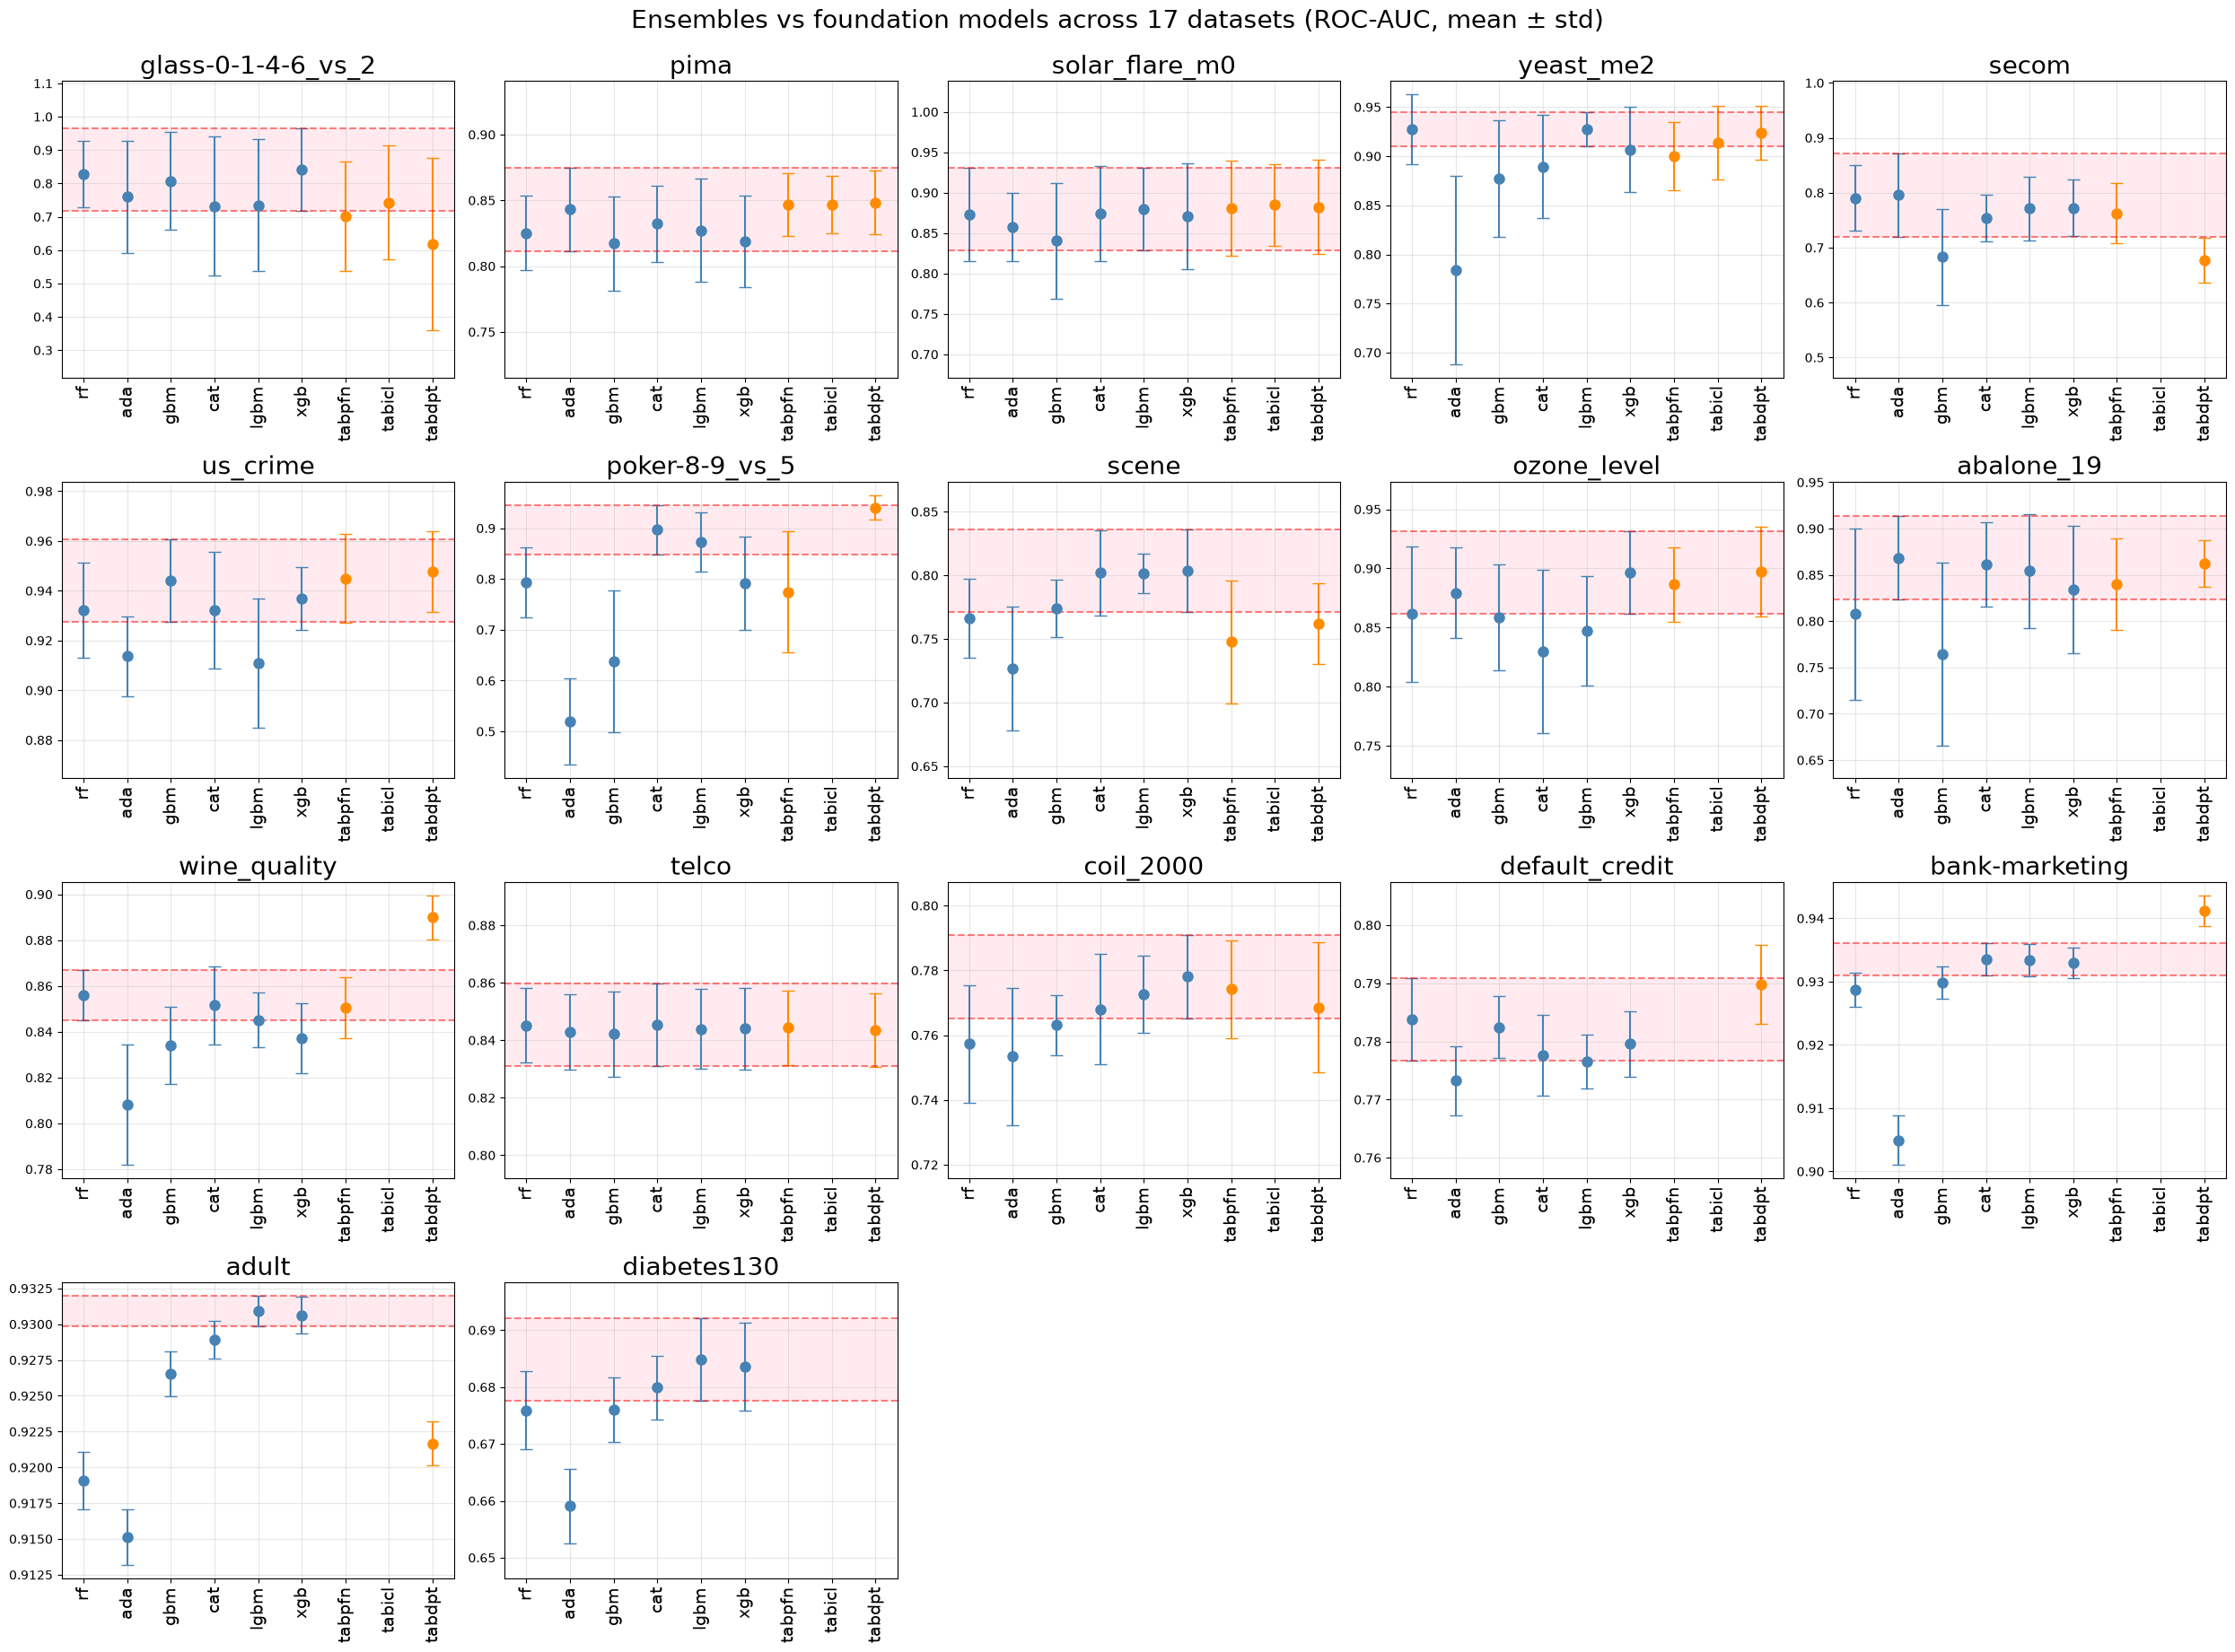

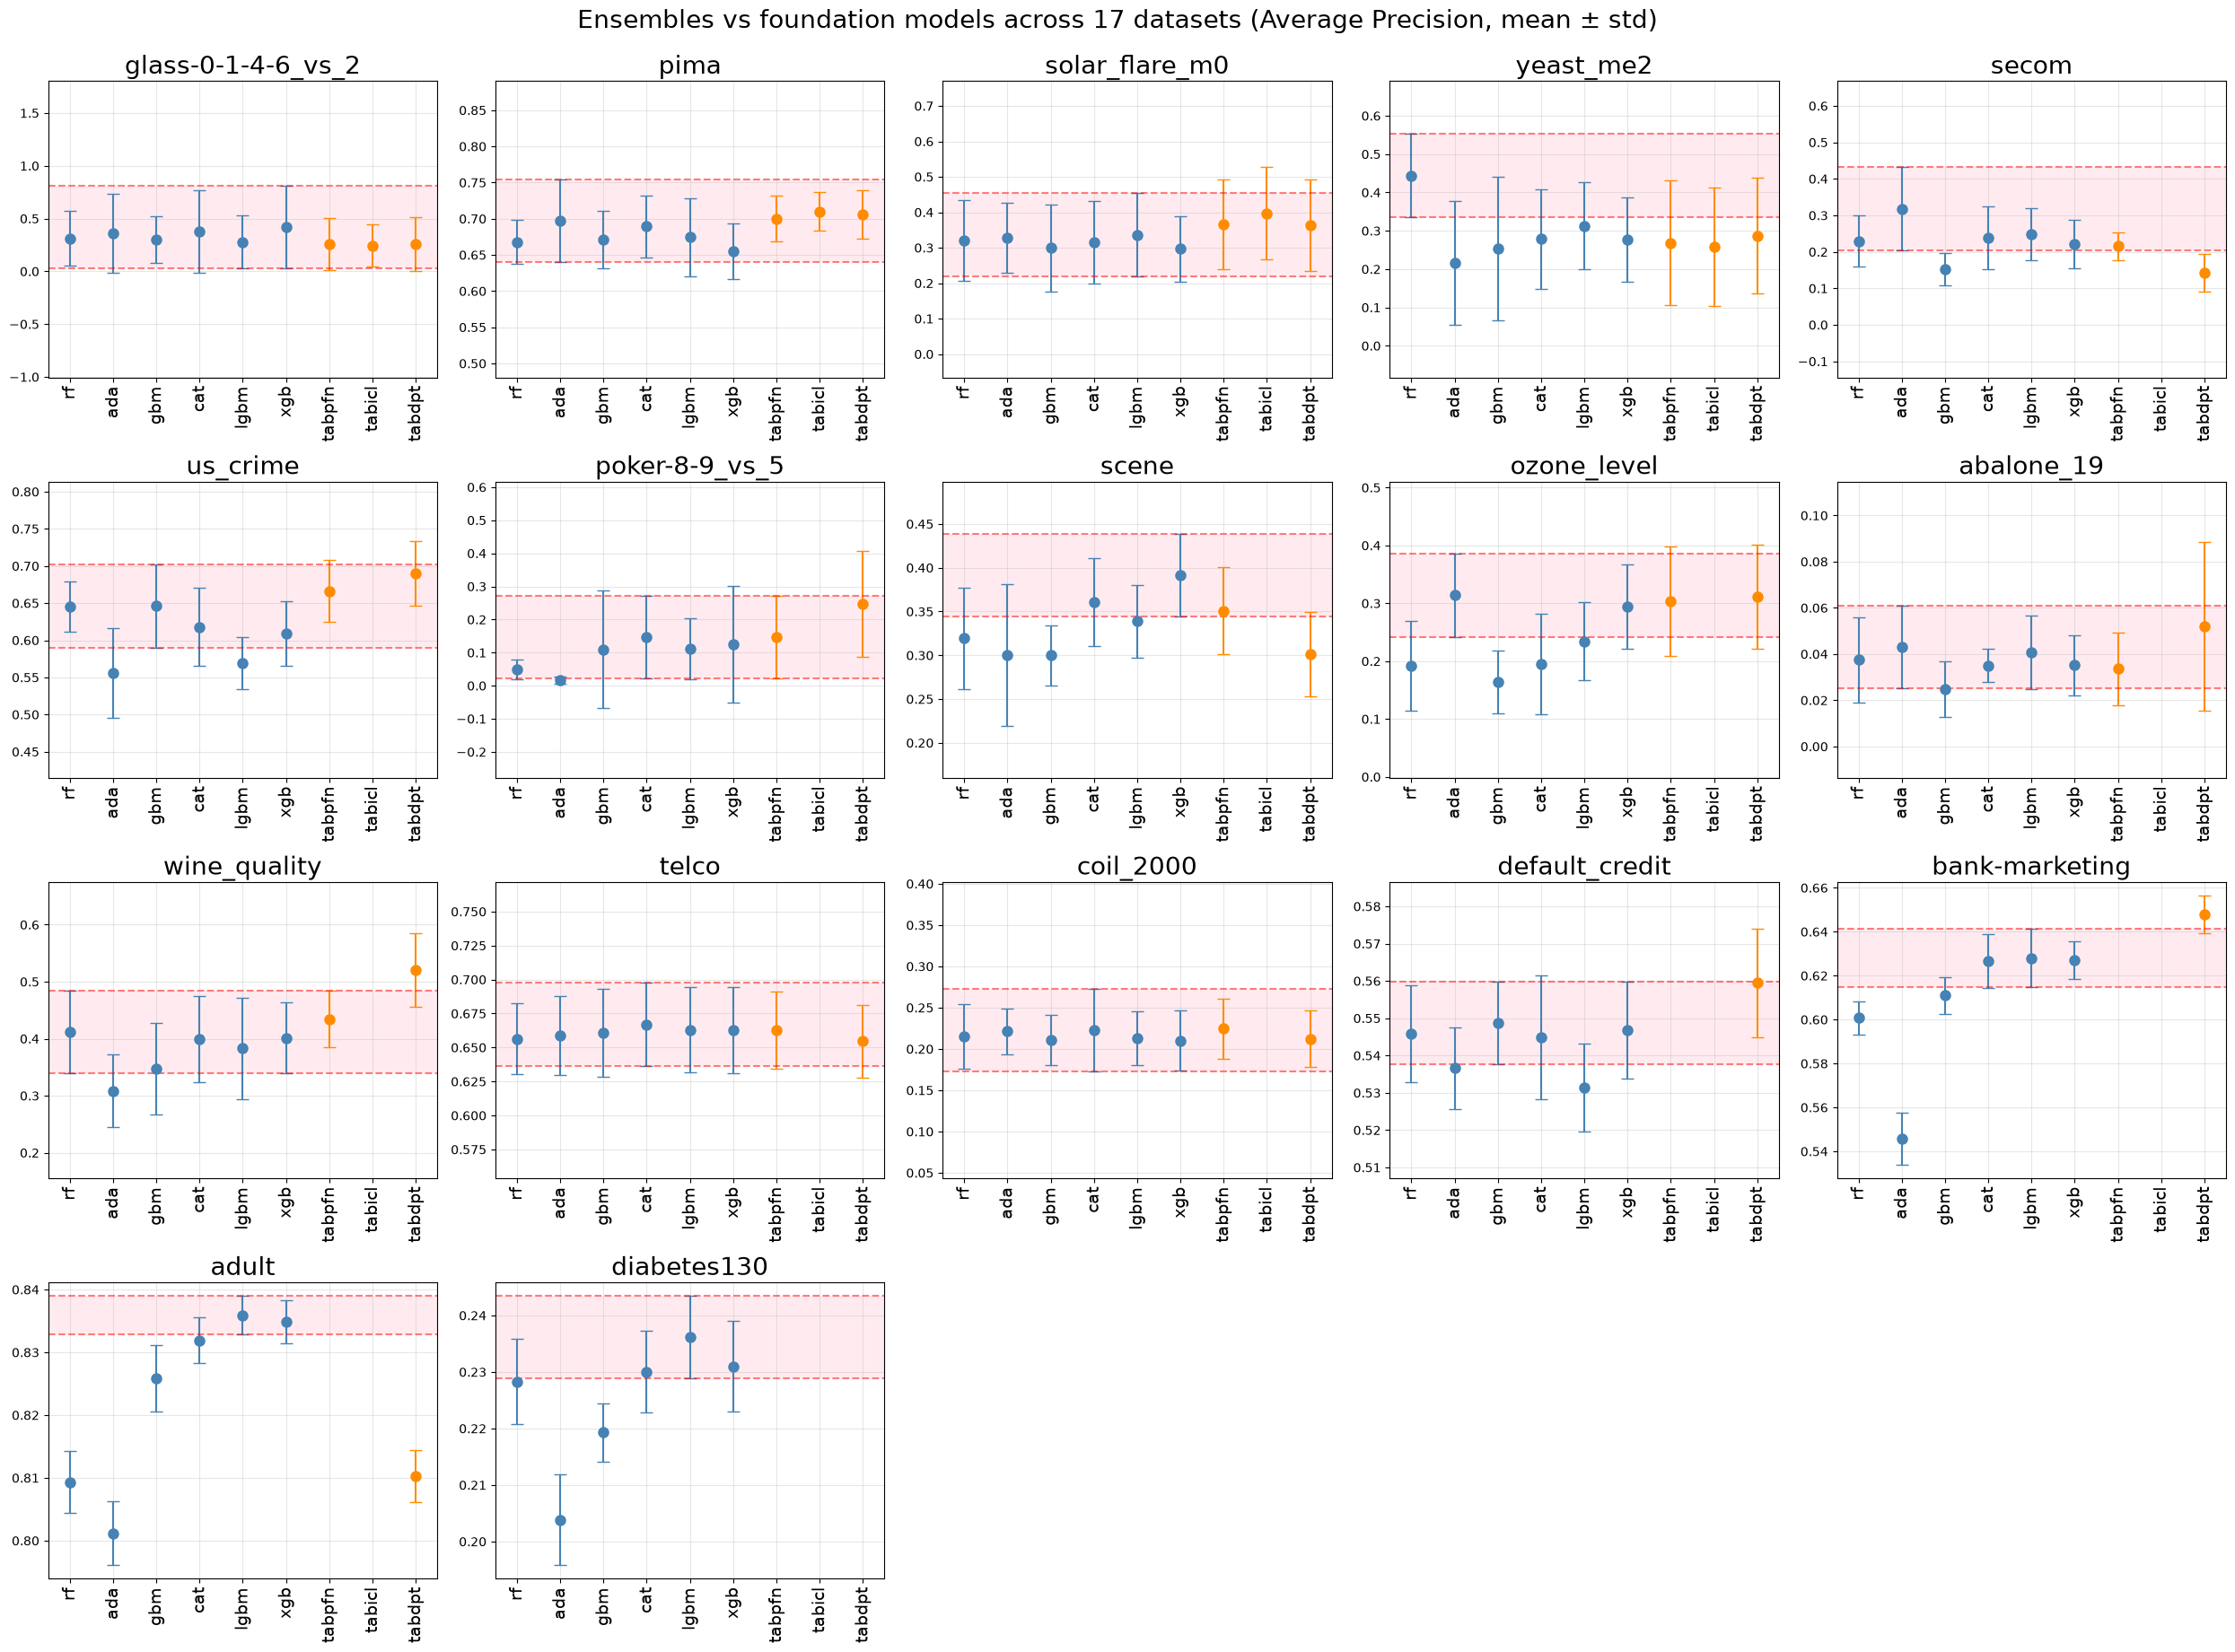

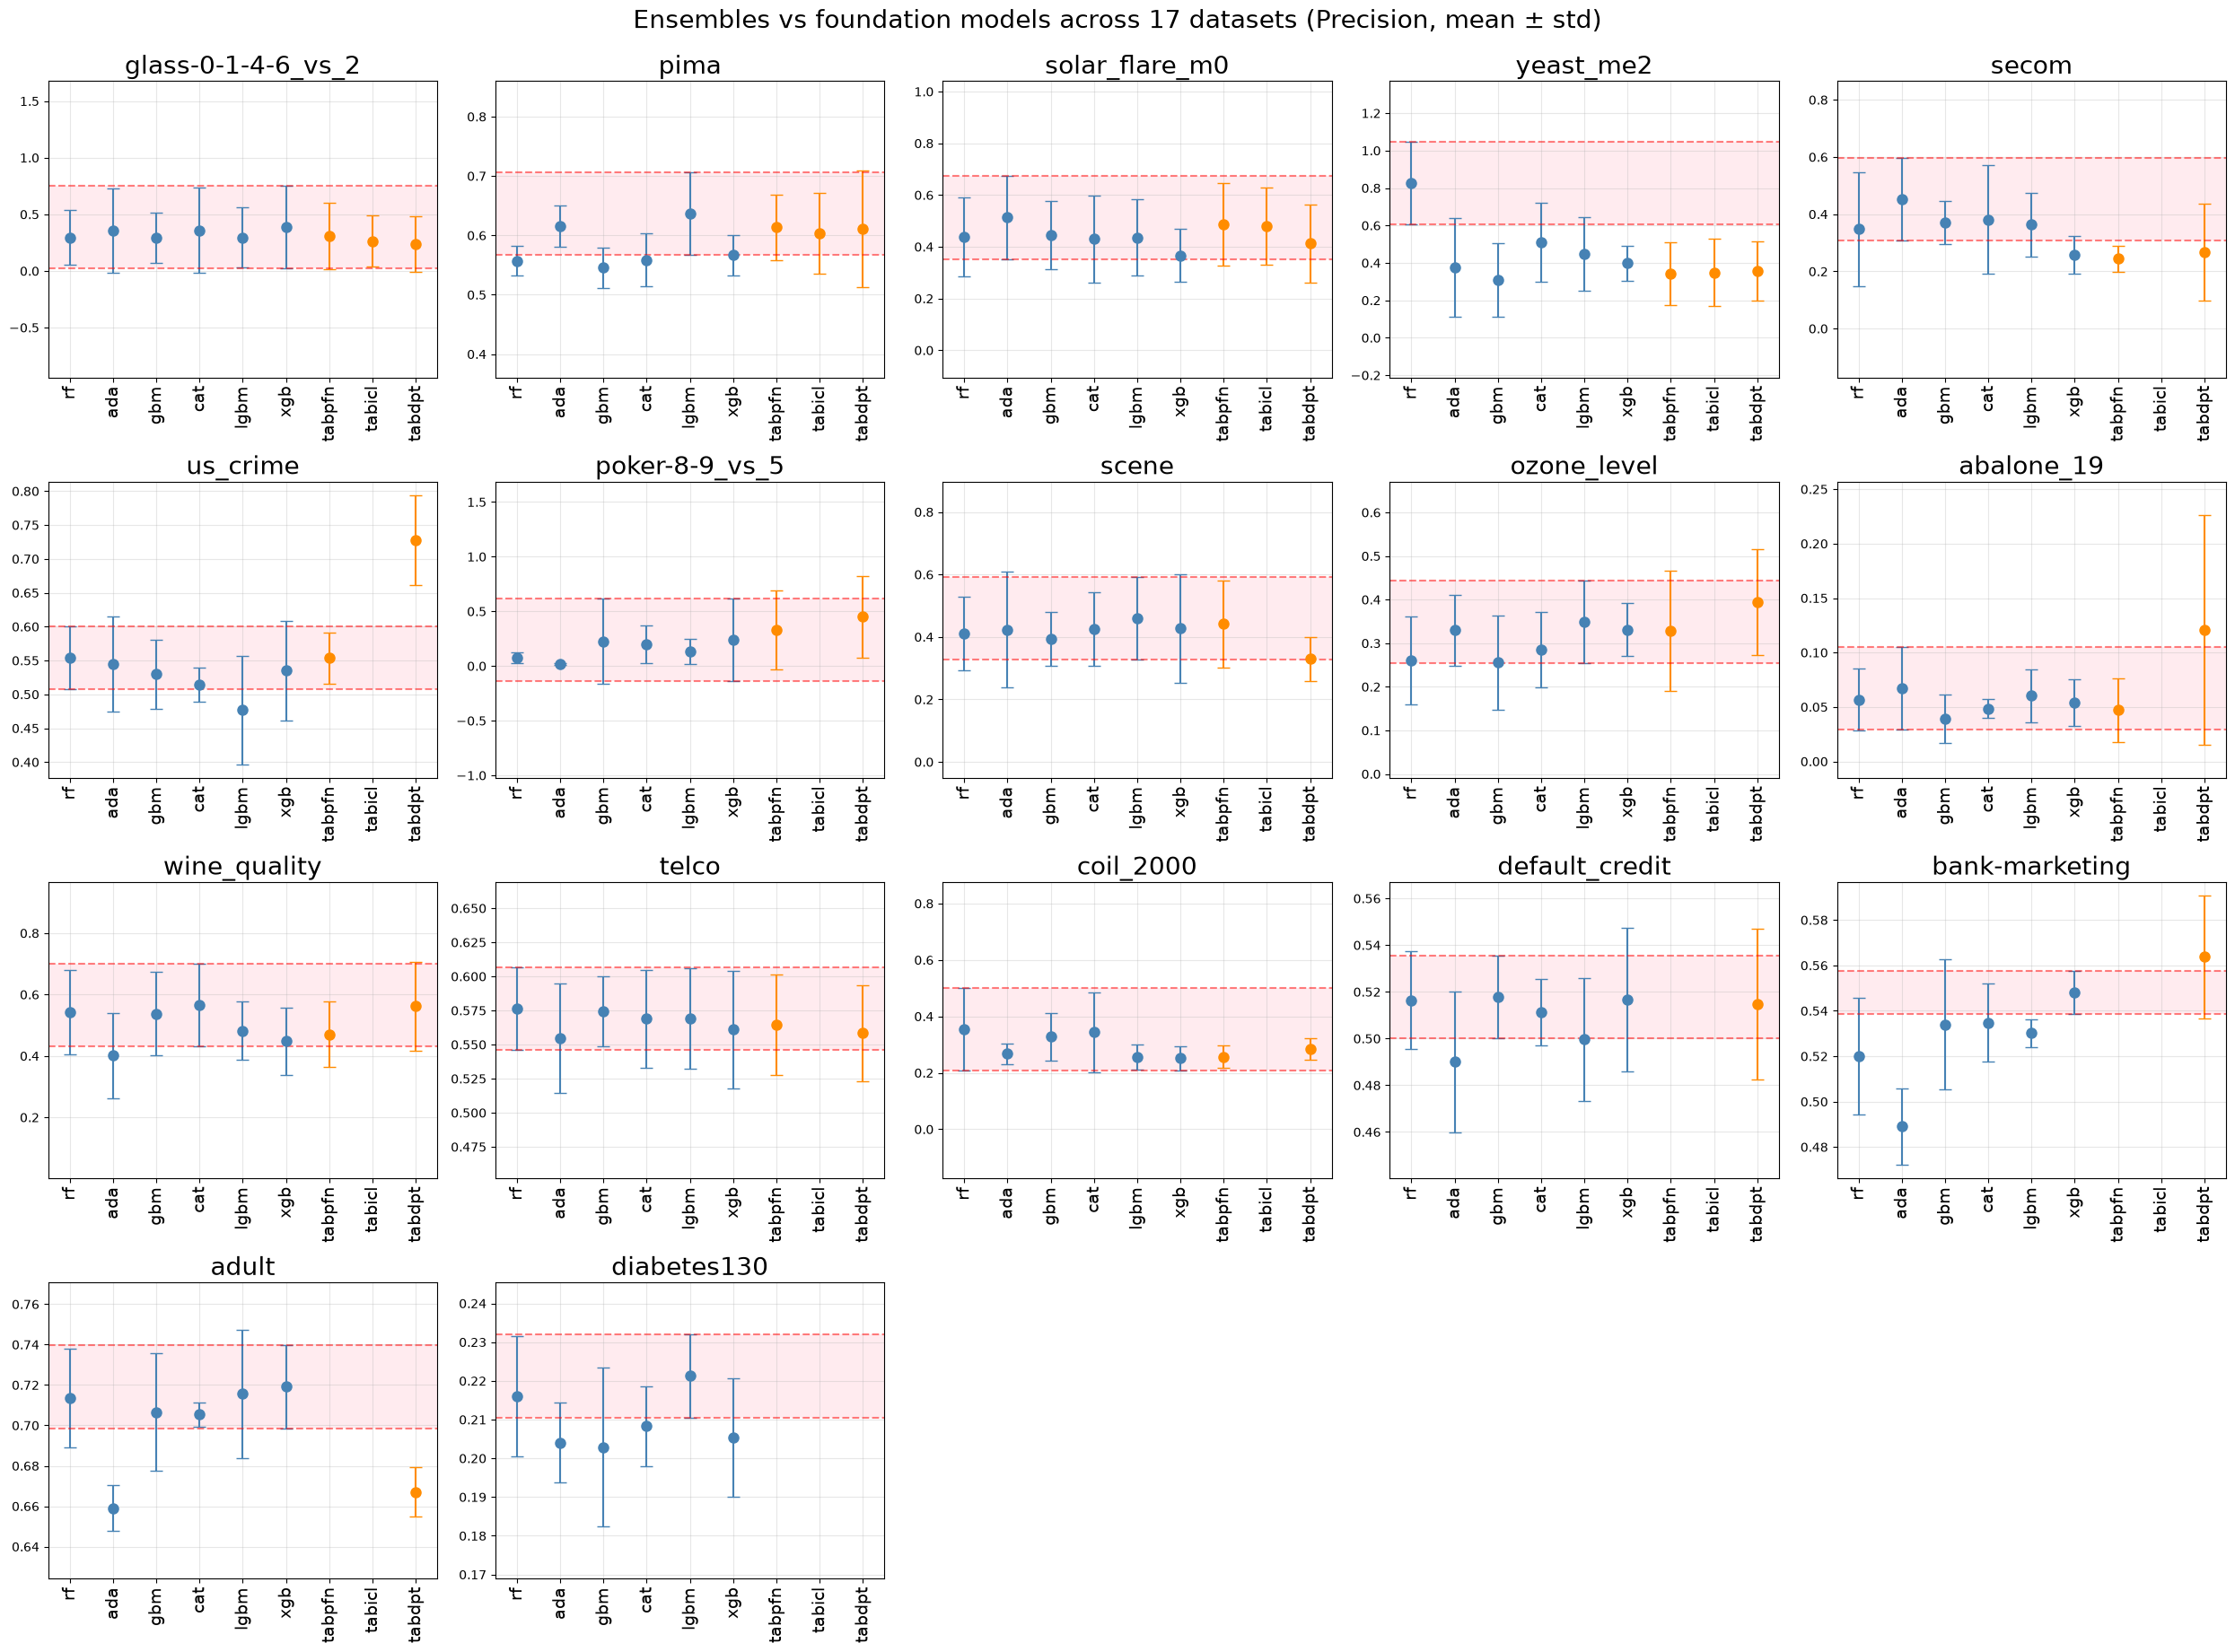

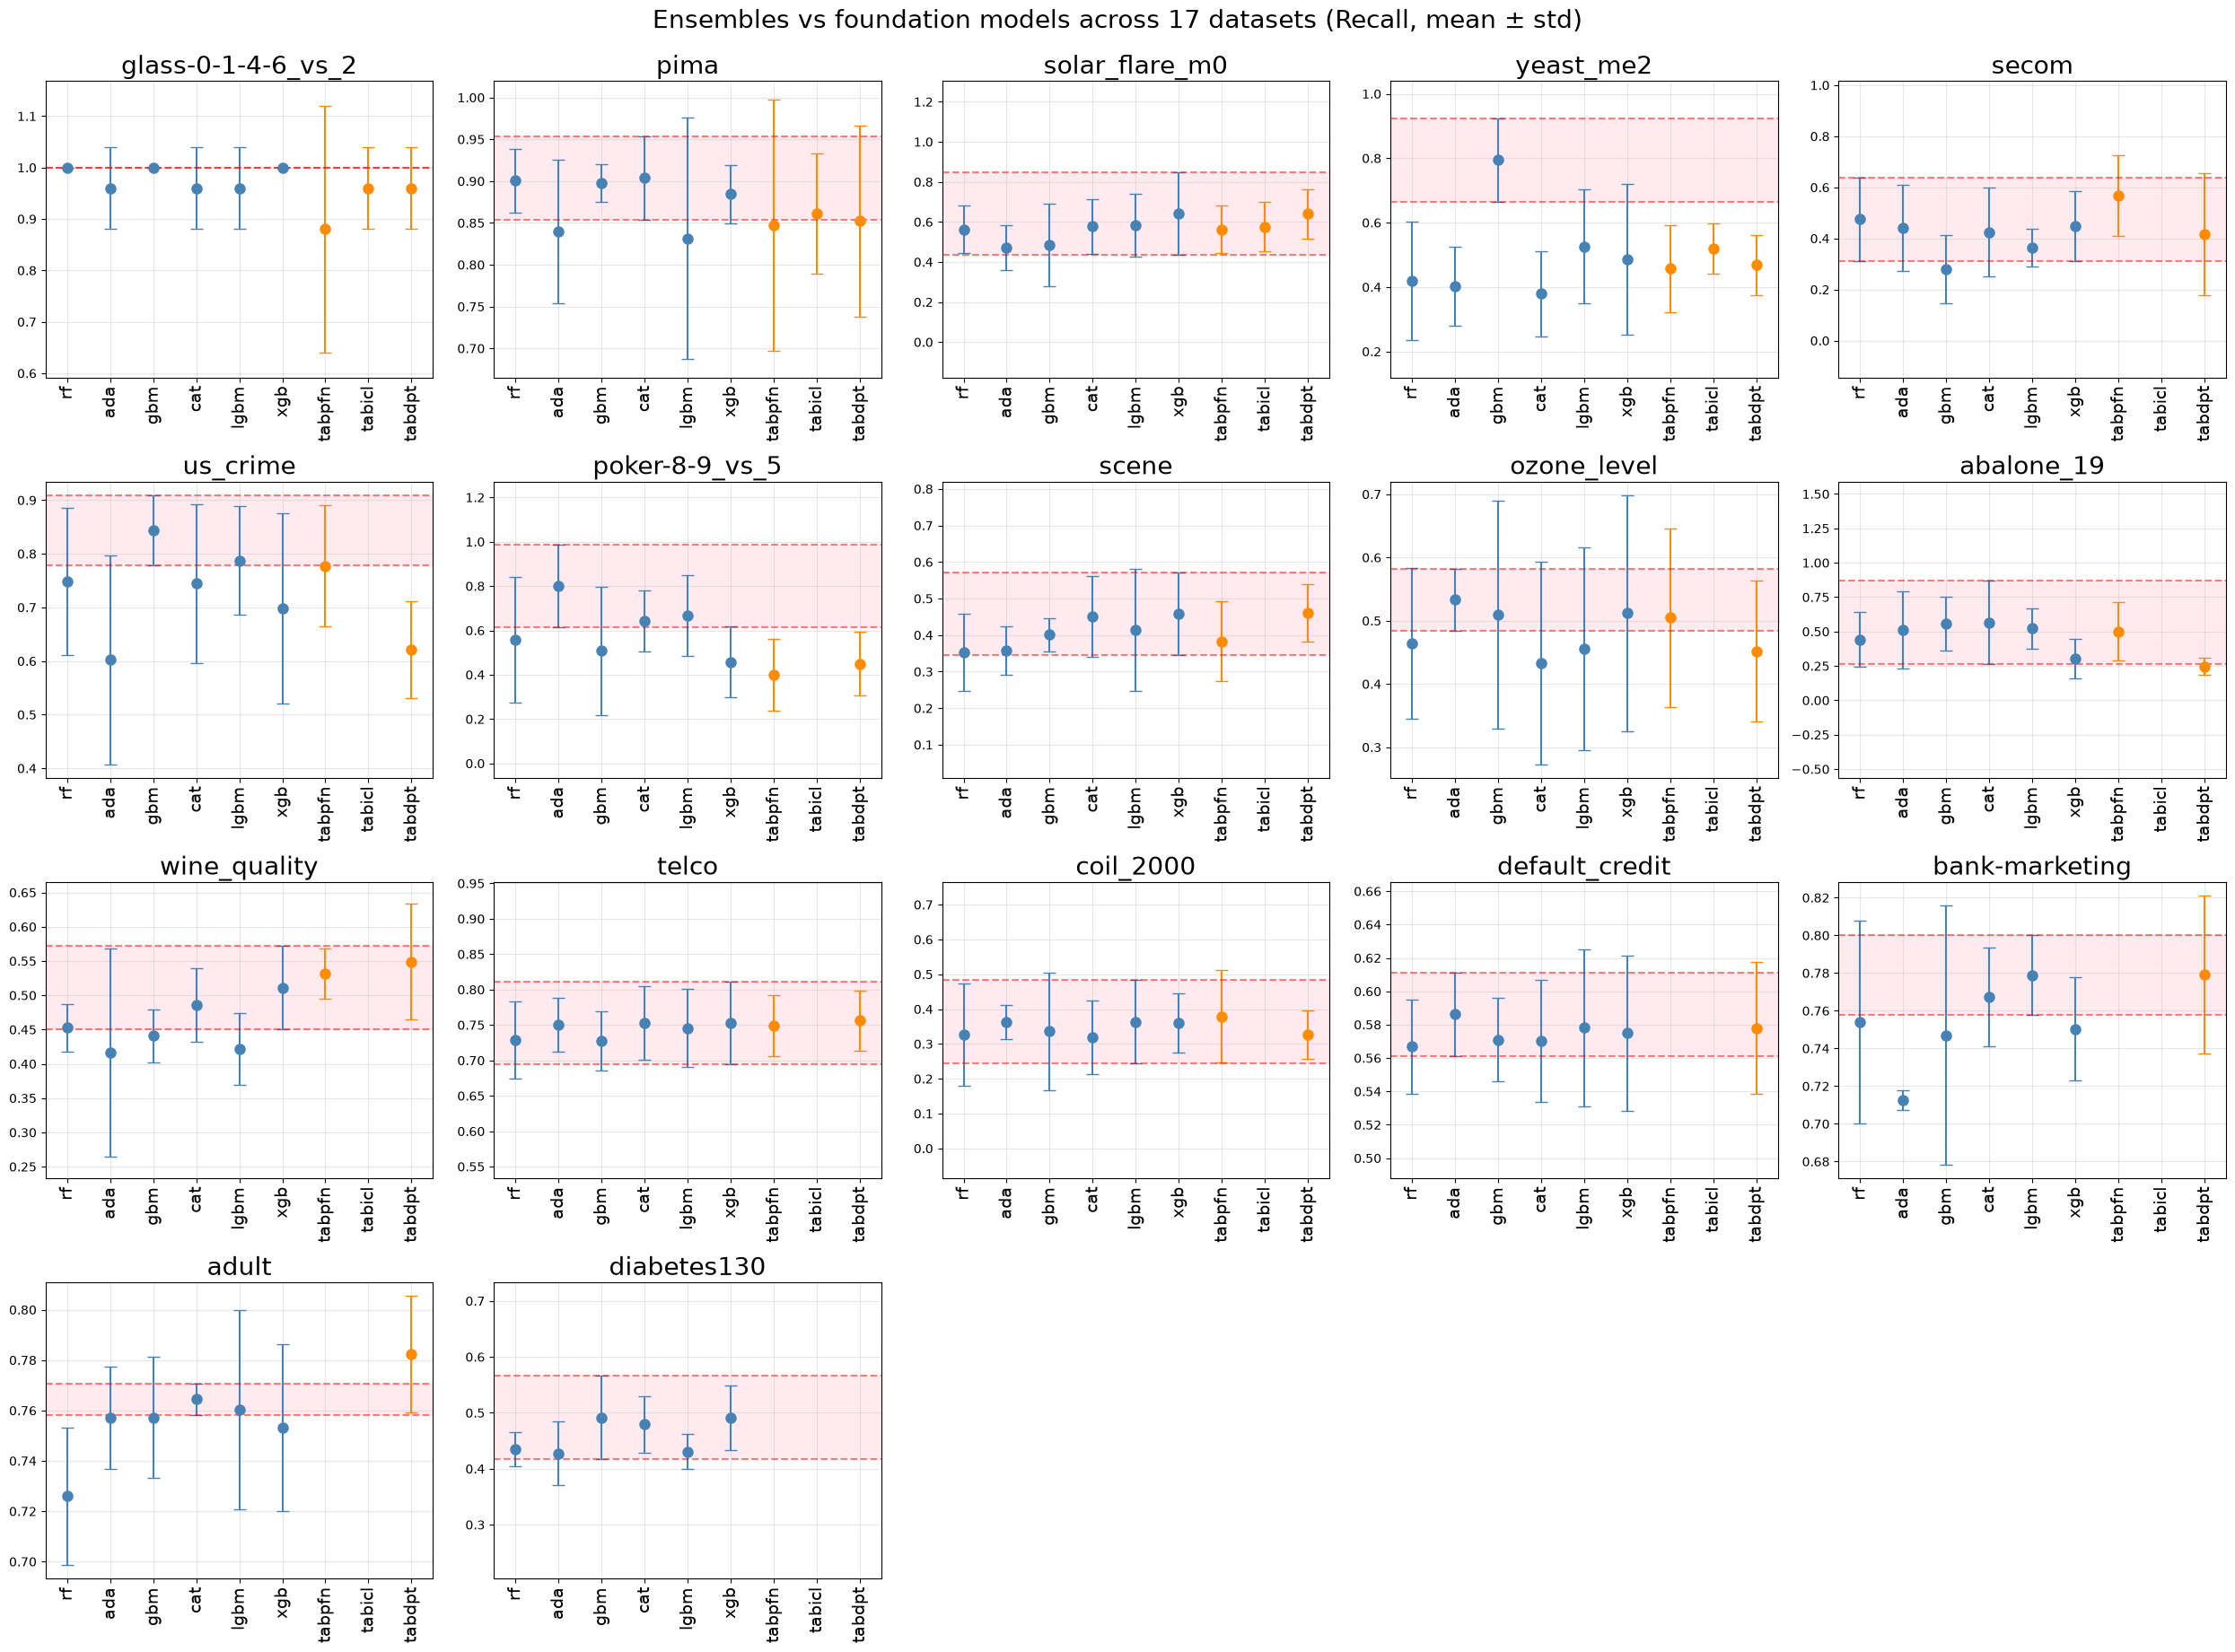

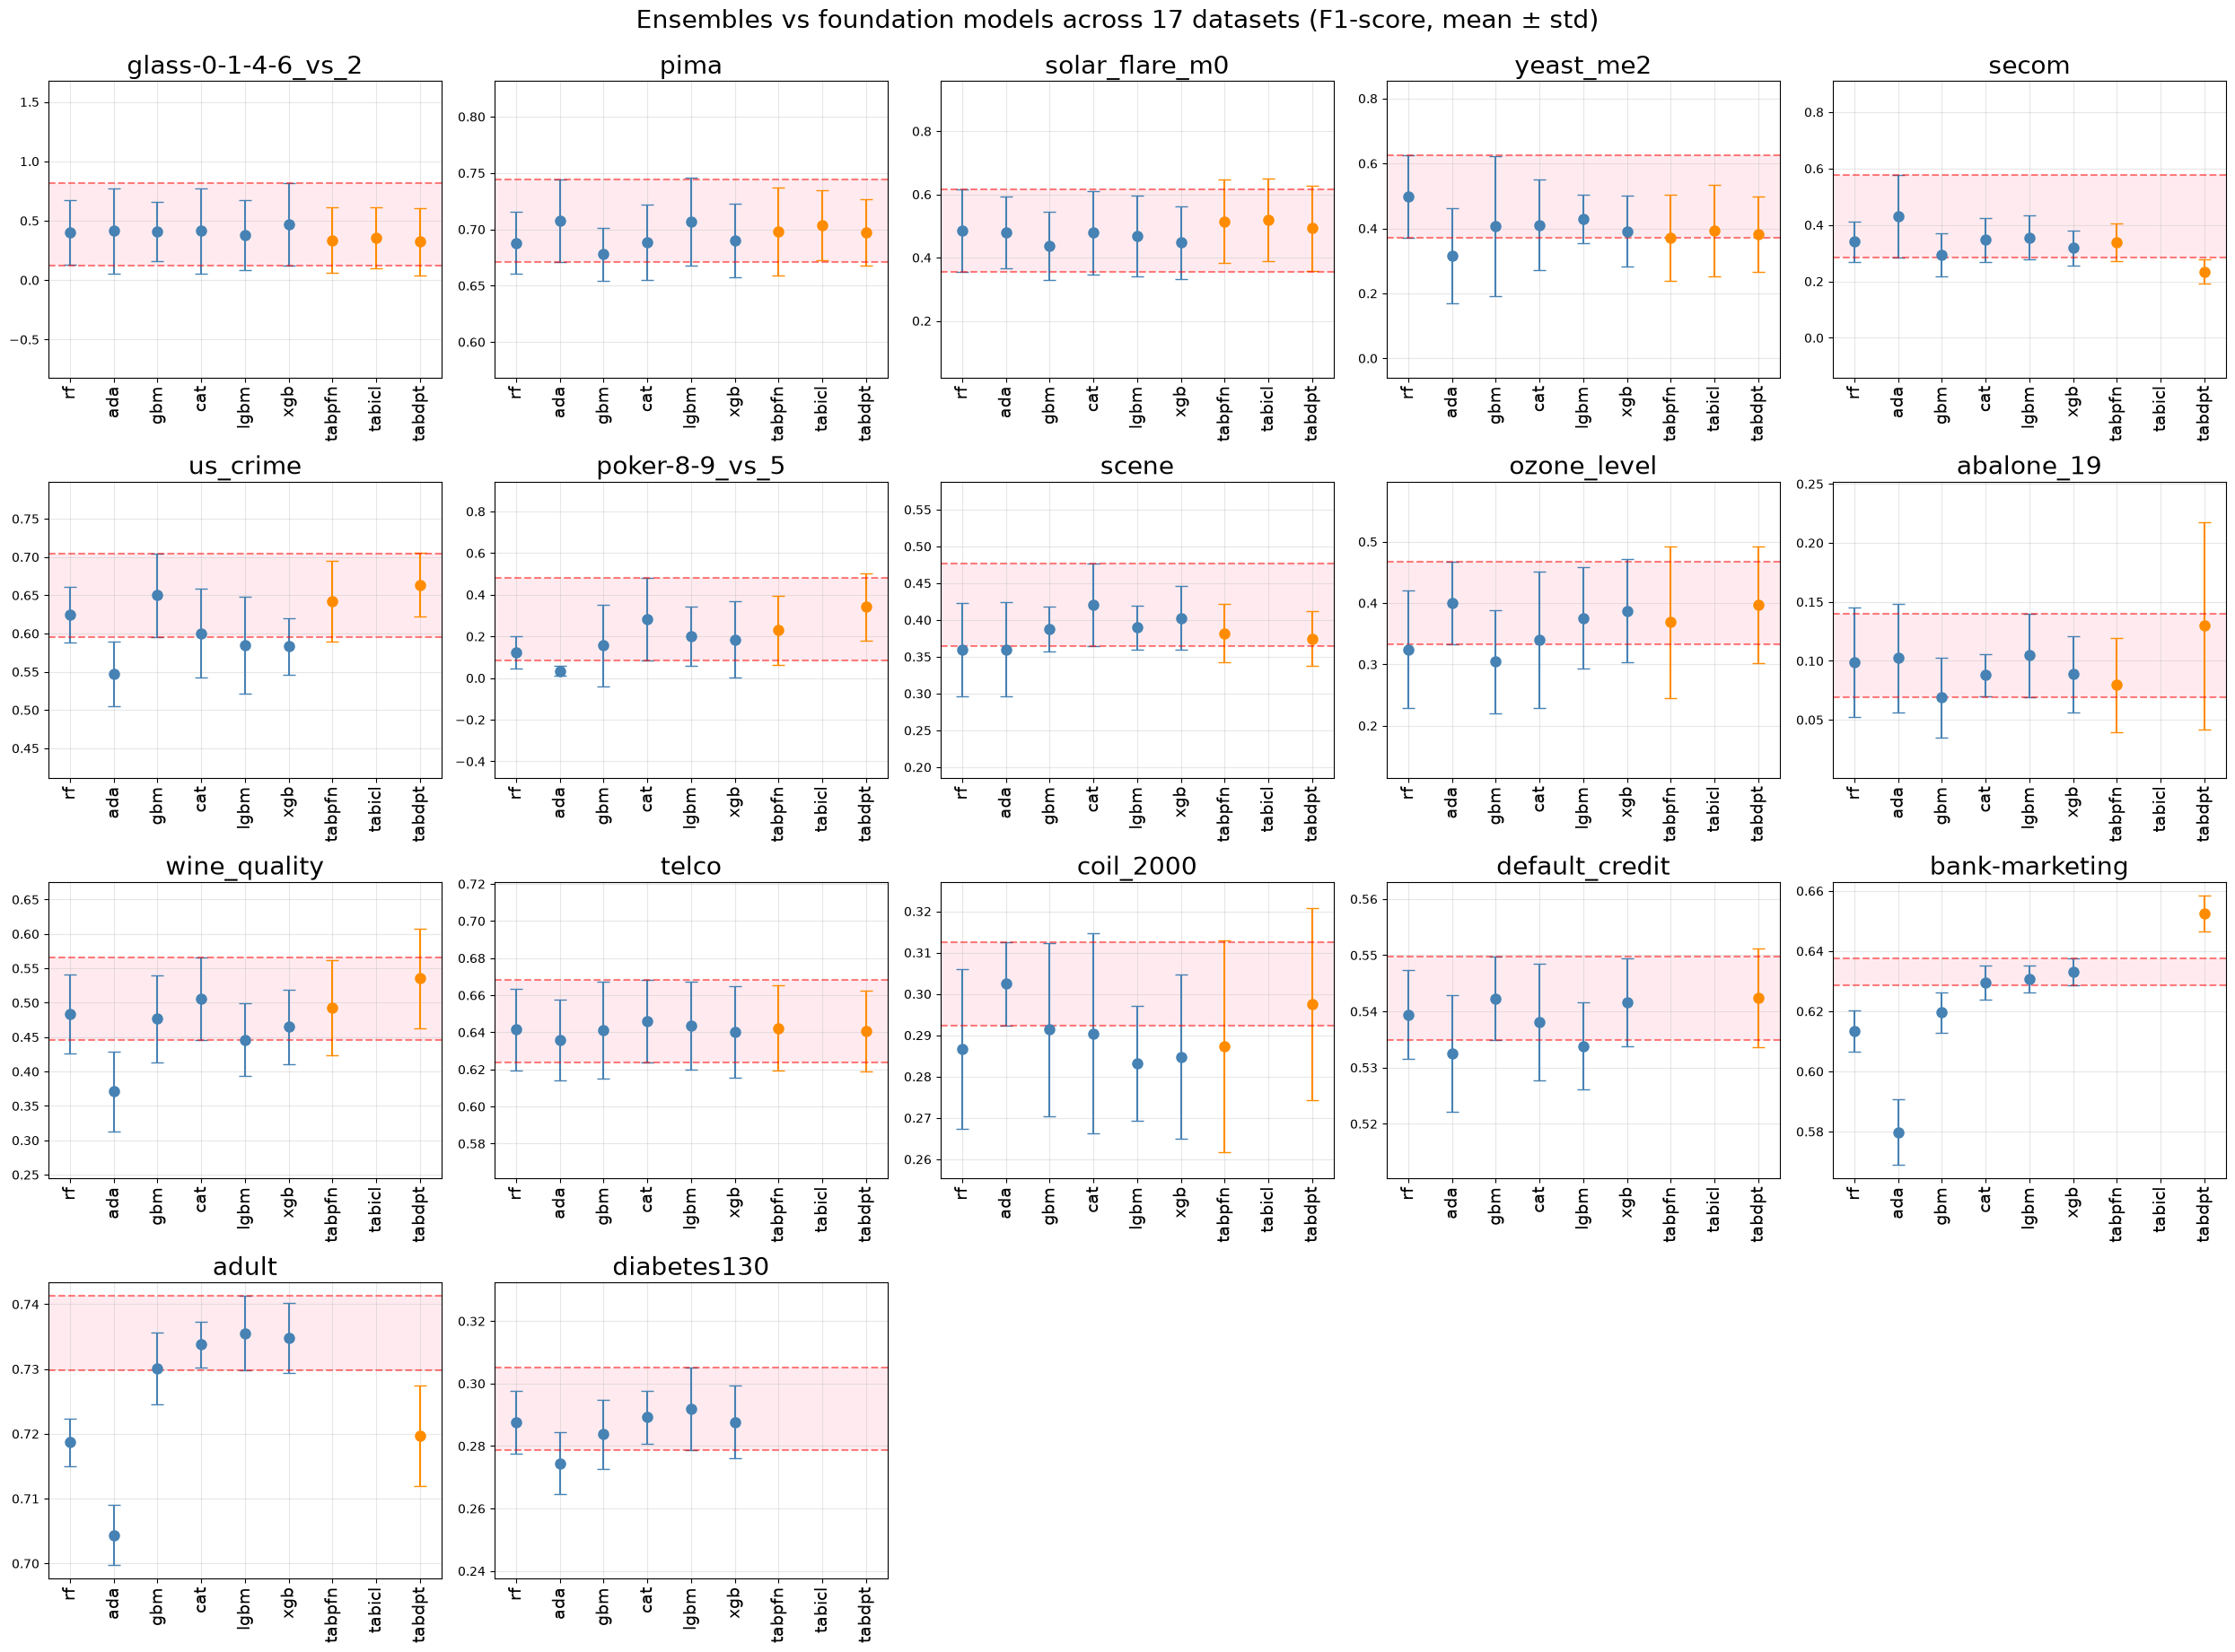

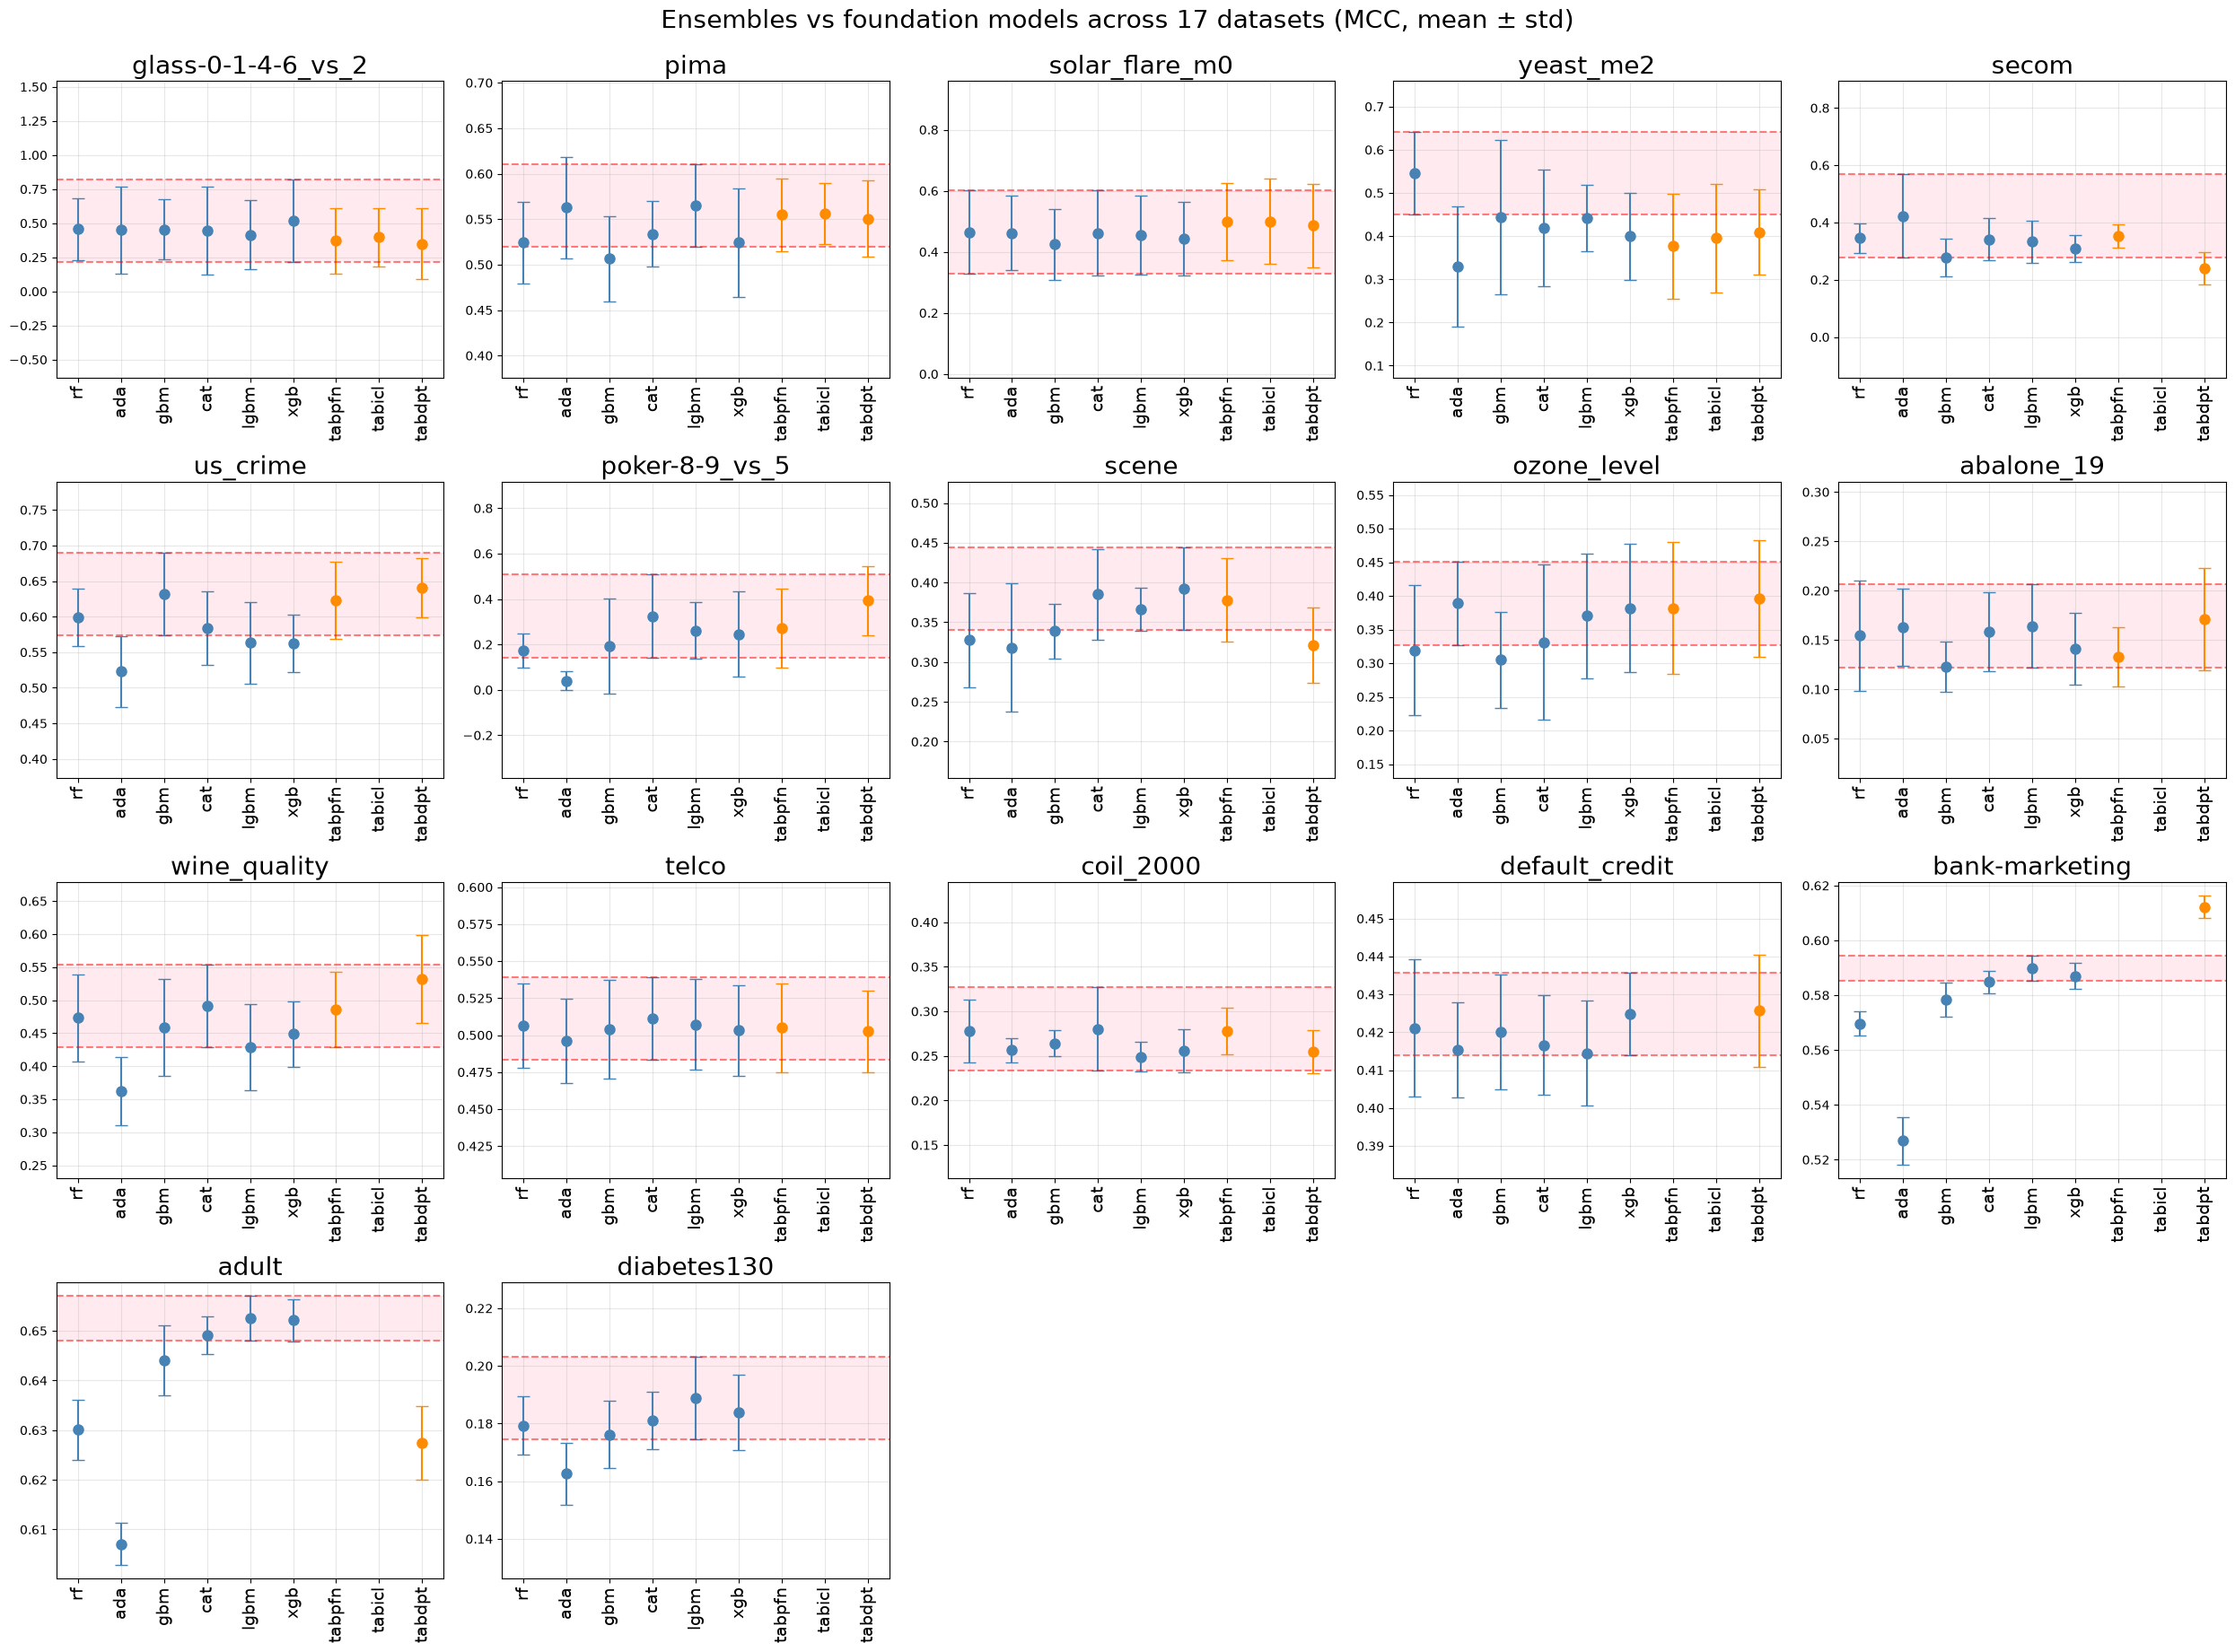

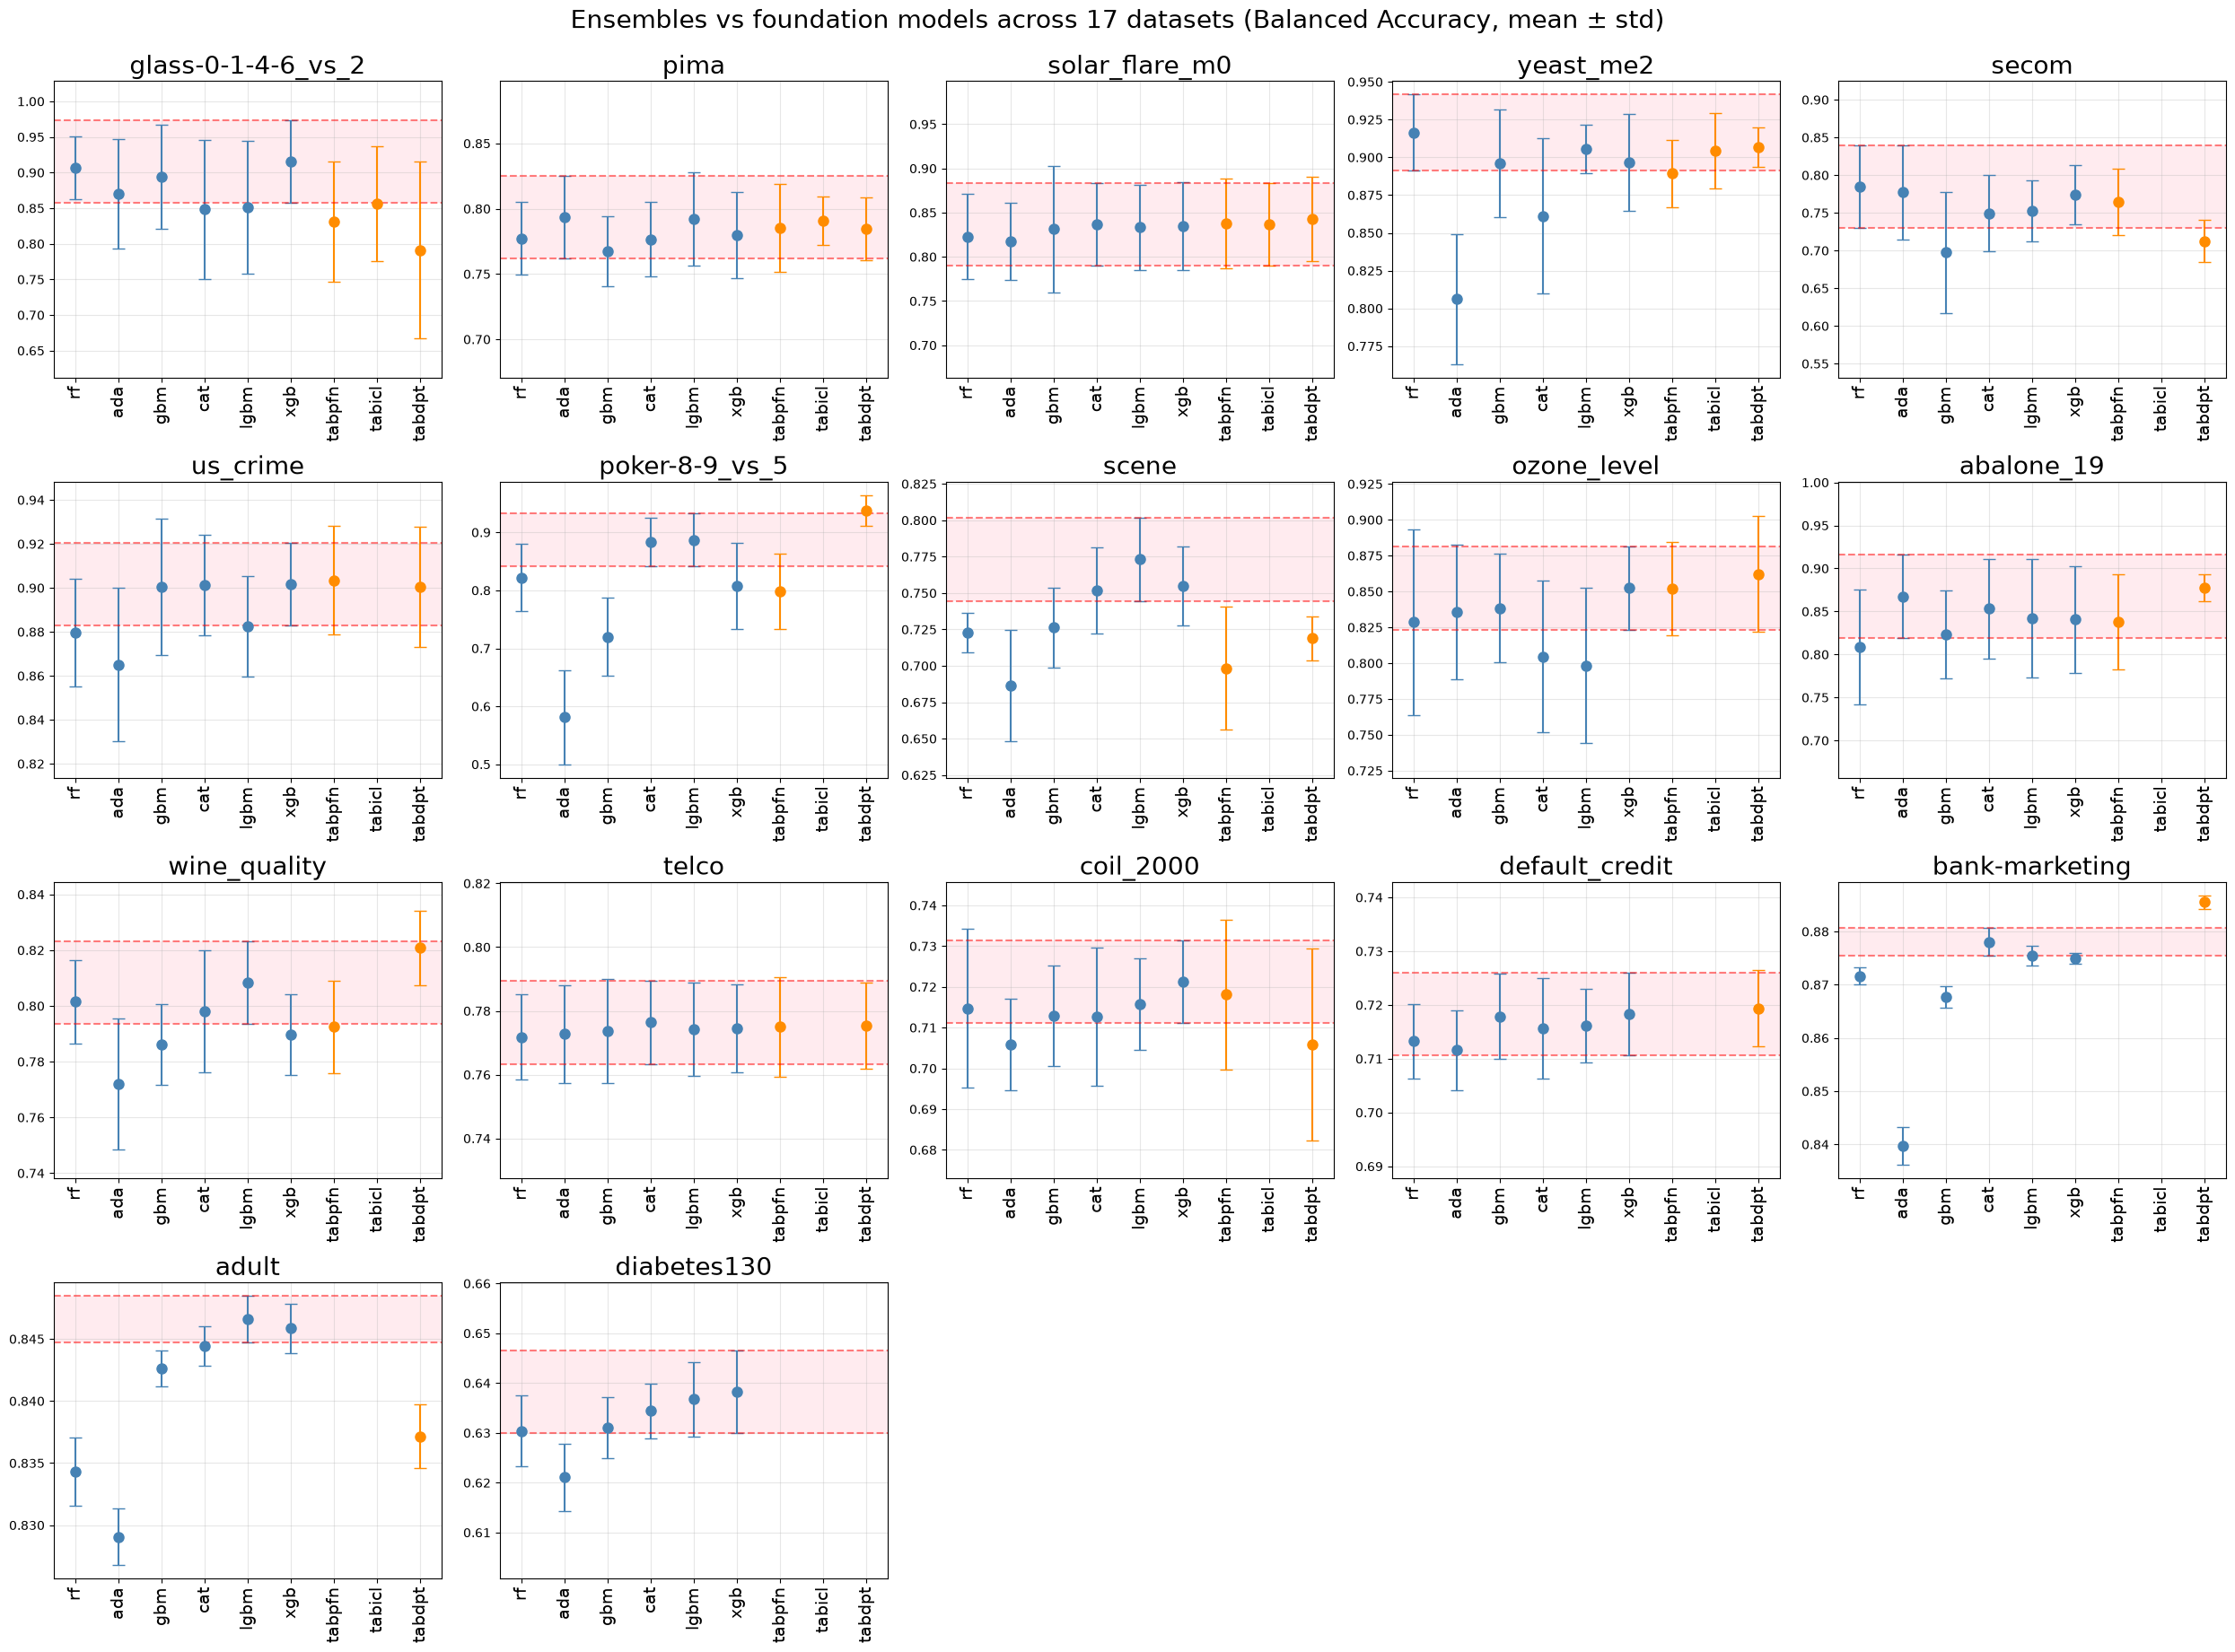

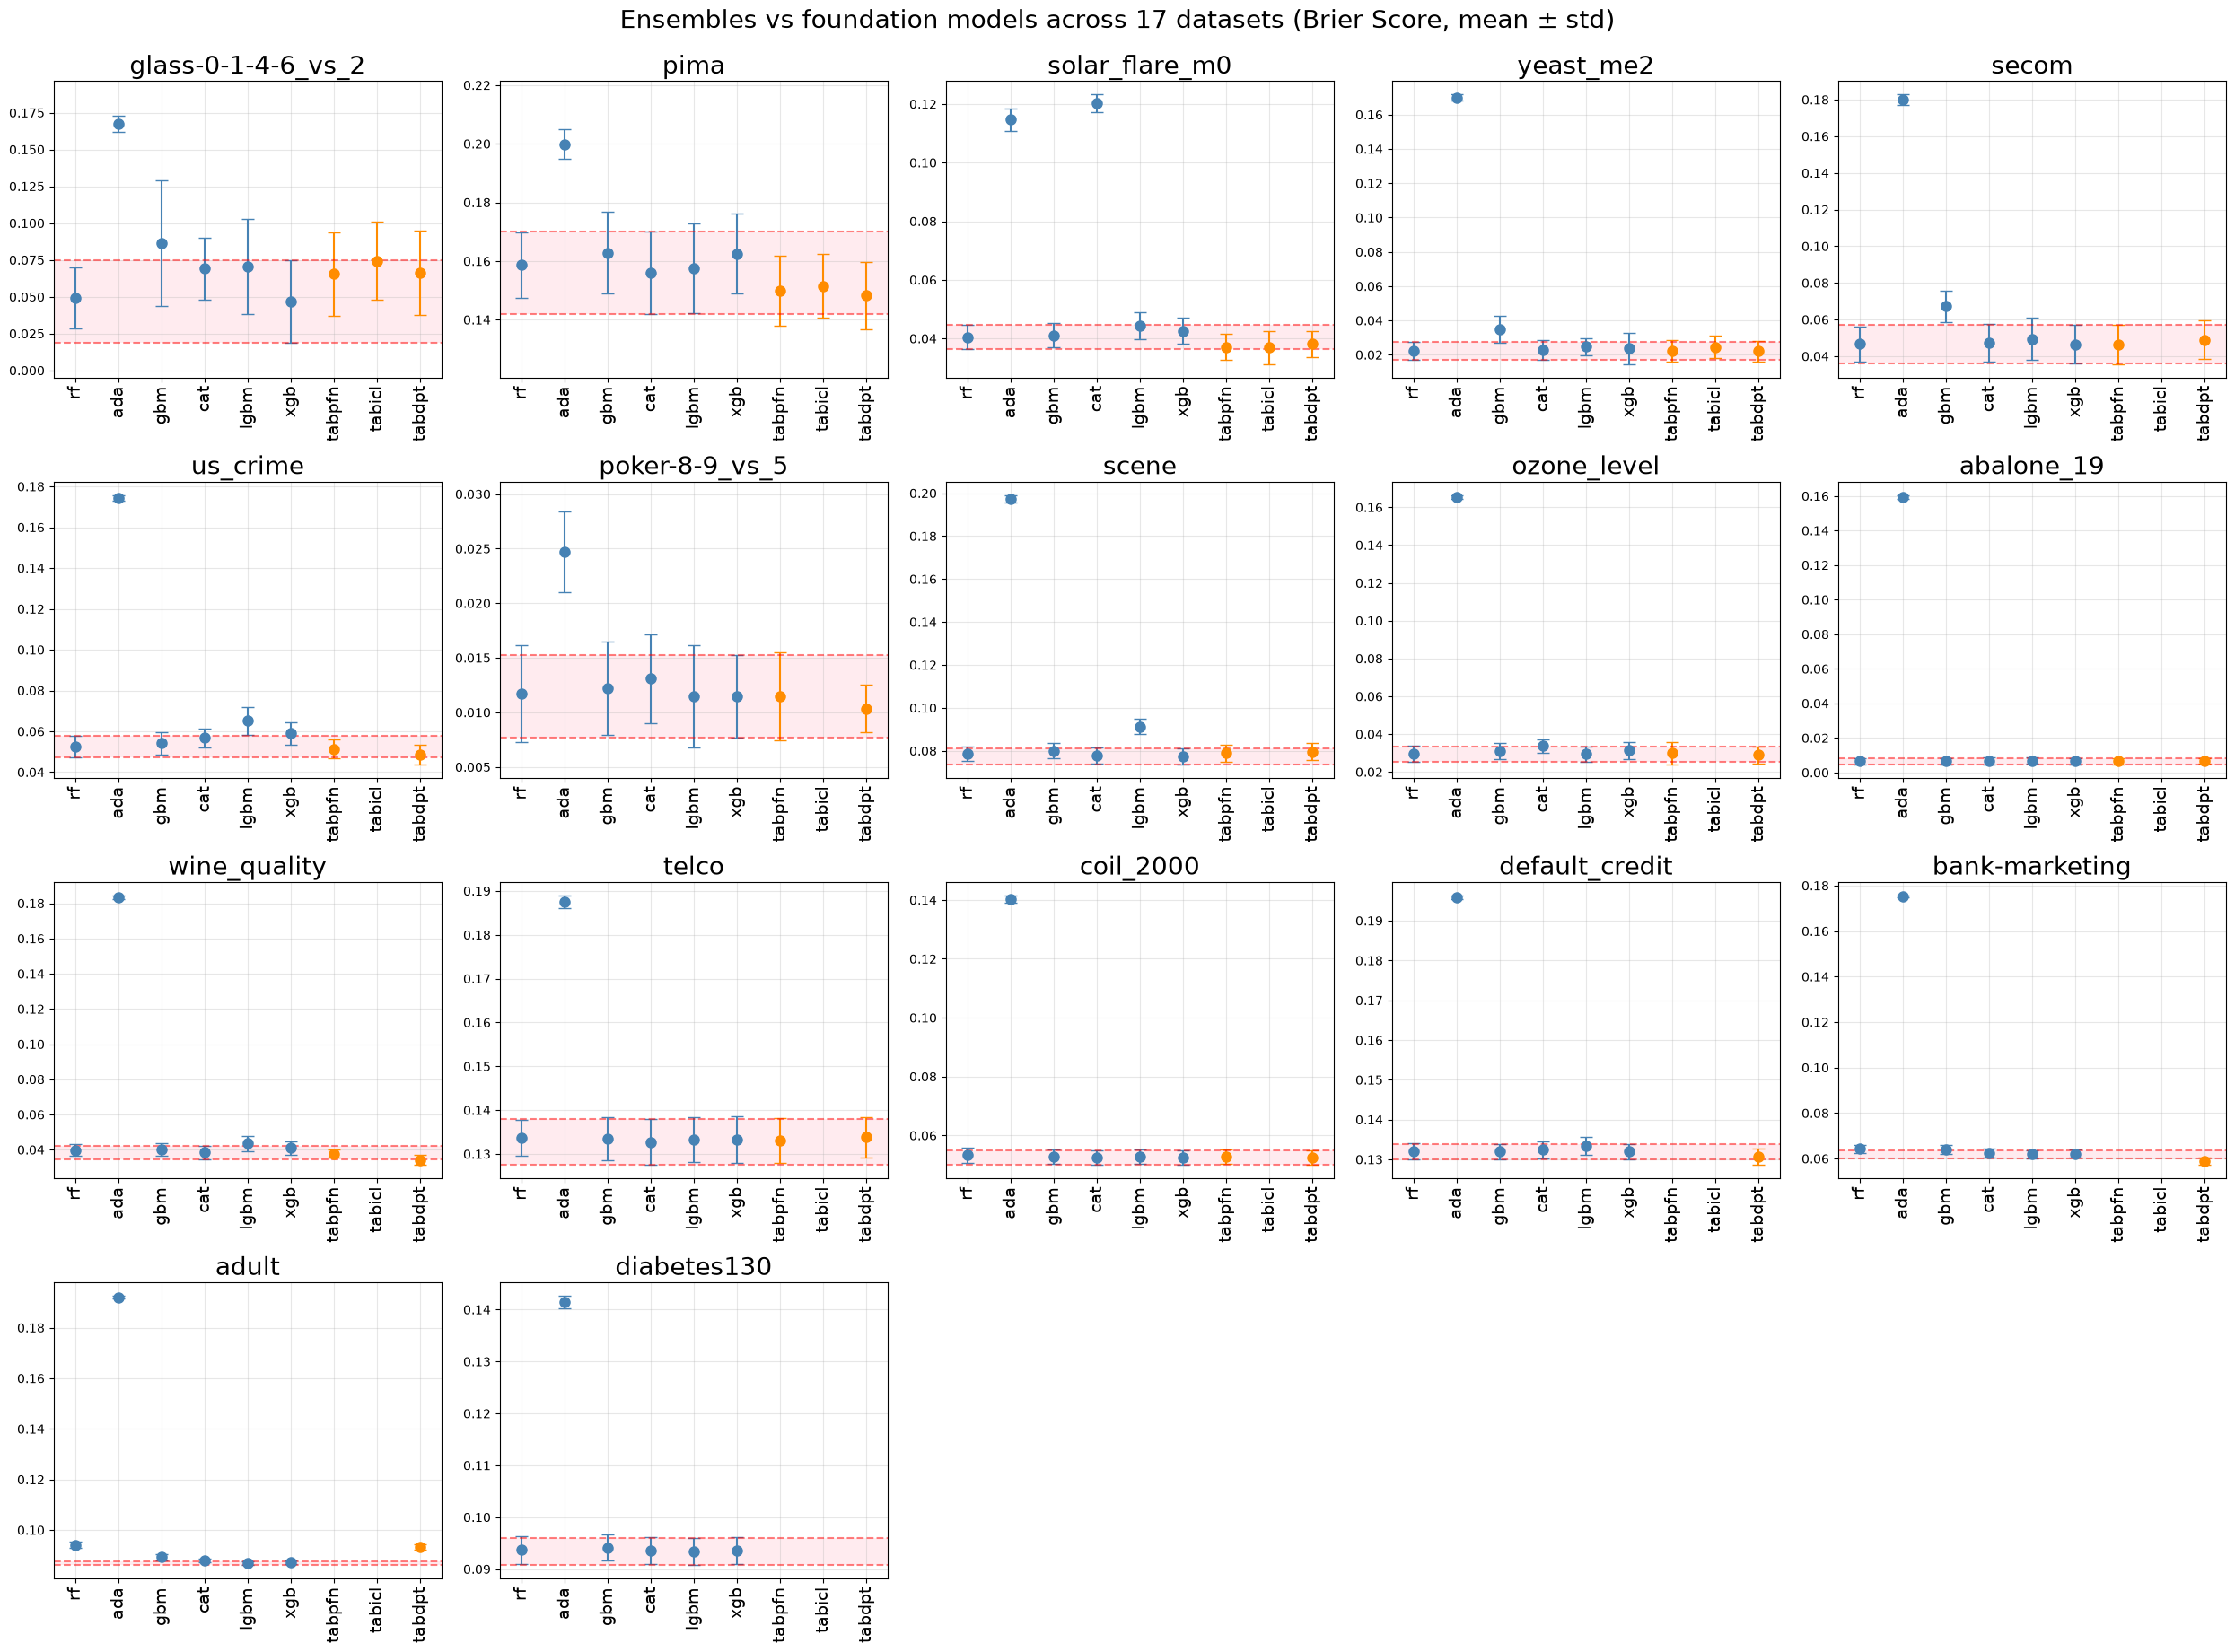

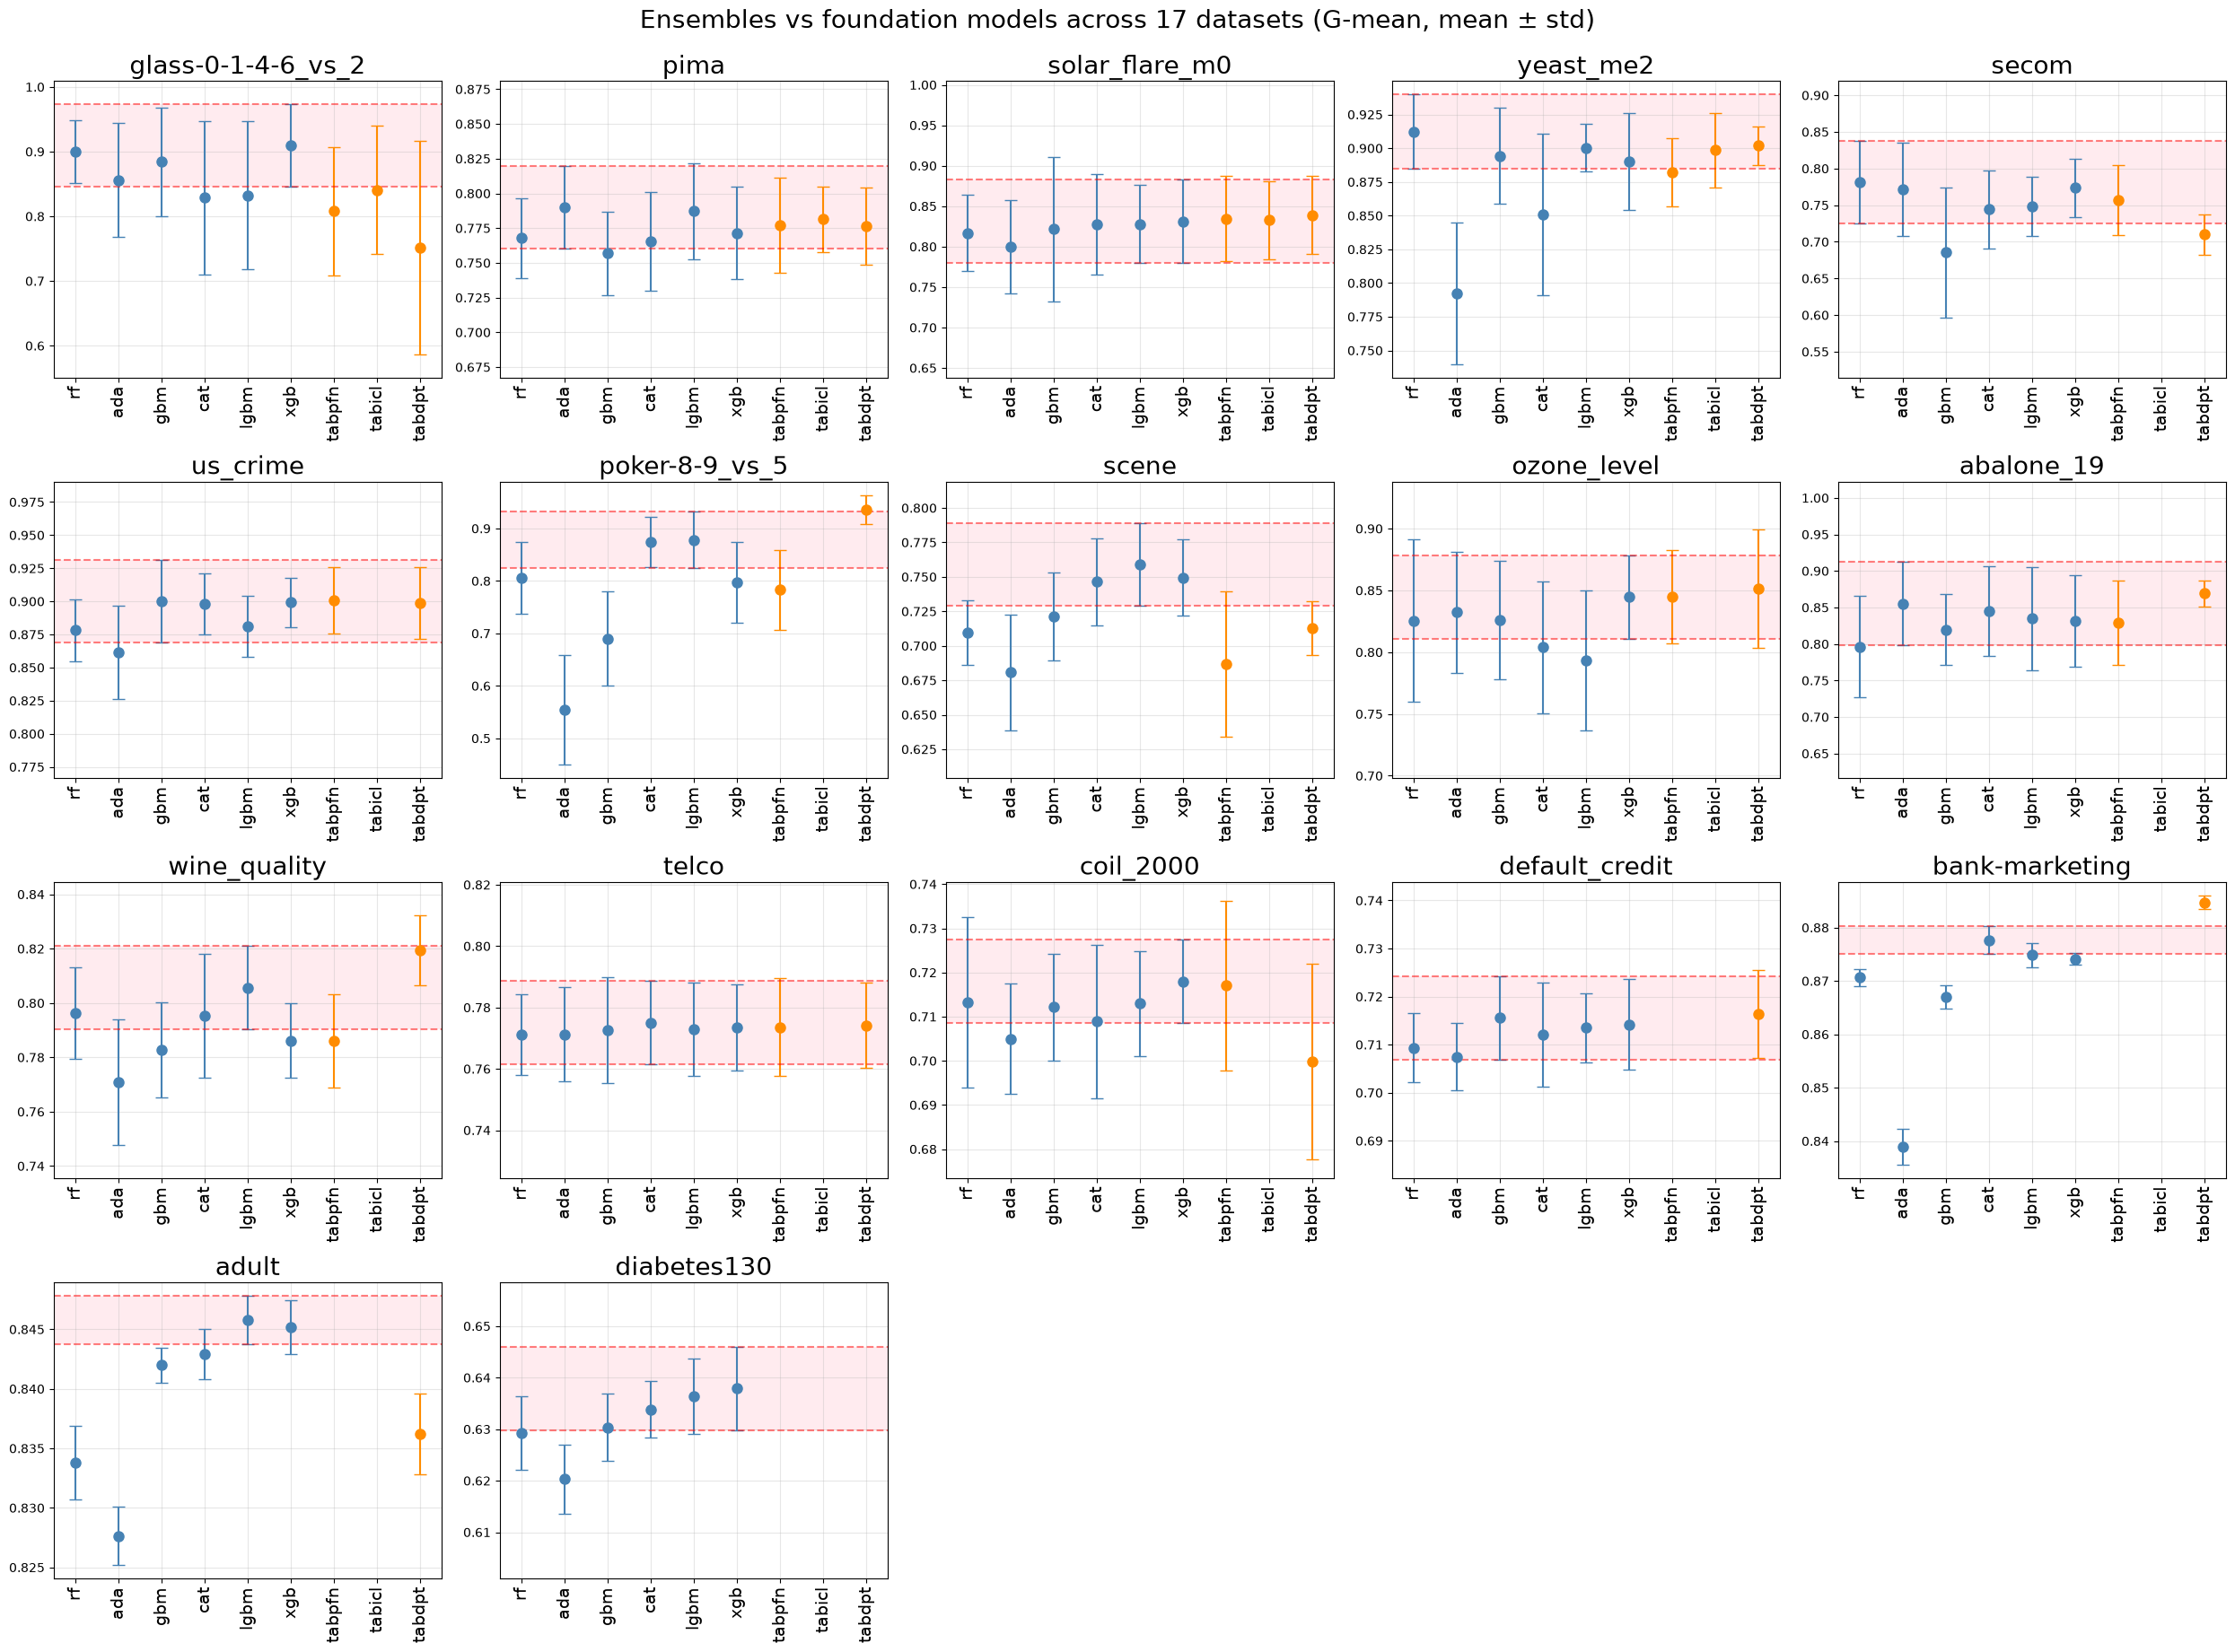

In [6]:
metrics = {
    "roc": ("roc", "roc_std", "ROC-AUC"),
    "ap": ("ap", "ap_std", "Average Precision"),
    "precision": ("precision", "precision_std", "Precision"),
    "recall": ("recall", "recall_std", "Recall"),
    "f1": ("f1_score", "f1_std", "F1-score"),
    "mcc": ("mcc", "mcc_std", "MCC"),
    "ba": ("ba", "ba_std", "Balanced Accuracy"),
    "brier": ("brier", "brier_std", "Brier Score"),
    "gmean": ("gmean", "gmean_std", "G-mean"),
}
models = ensembles + ["tabpfn", "tabicl", "tabdpt"]
colors = ["steelblue"] * len(ensembles) + ["darkorange"] * 3

for metric, (mean_col, std_col, label) in metrics.items():
    fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25, 18))
    axes = axes.ravel()

    for i, data in enumerate(datasets):
        d = df.xs(data, level="dataset").reindex(models)
        means, stds = d[mean_col], d[std_col]

        # pink area: best ensemble on this metric
        ens_means = means[ensembles]
        b = ens_means.idxmin() if metric == "brier" else ens_means.idxmax()
        upper, lower = means[b] + stds[b], means[b] - stds[b]

        ax = axes[i]
        for m, c in zip(models, colors):
            ax.errorbar(x=[m], y=[means[m]], yerr=[stds[m]], fmt="o", capsize=5, markersize=8, color=c)

        # show every model, also those that could not run on this dataset
        ax.set_xticks(range(len(models)), models)
        ax.set_xlim(-0.5, len(models) - 0.5)
        ax.set_title(data, fontsize=20)
        ax.set_ylim(compute_ylim(means, stds, upper, lower))
        ax.tick_params(axis="x", rotation=90, labelsize=14)
        ax.grid(True, alpha=0.3)
        ax.axhline(y=upper, color="r", linestyle="--", alpha=0.5)
        ax.axhline(y=lower, color="r", linestyle="--", alpha=0.5)
        ax.axhspan(ymin=lower, ymax=upper, facecolor="pink", alpha=0.3)

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.suptitle(f"Ensembles vs foundation models across {len(datasets)} datasets ({label}, mean ± std)", fontsize=20, y=1.02)
    plt.savefig(f"../figures/tfm_{metric}.png", dpi=300, bbox_inches="tight")
    plt.show()

## TabPFN-2 and TabDPT vs the ensembles

For each model and metric: the median difference (foundation model - ensemble) across the datasets where the foundation model ran (13 for TabPFN-2, 16 for TabDPT), the number of datasets where the foundation model is better (higher ROC-AUC and AP, lower Brier score) or worse, and the p-value of a paired Wilcoxon signed-rank test.

In [7]:
rows = []
for model in ["tabpfn", "tabdpt"]:
  for metric, sign in [("roc", 1), ("ap", 1), ("brier", -1)]:
    t = df.xs(model, level="model")[metric]
    for m in ensembles + ["best"]:
        e = df.xs(m, level="model")[metric].loc[t.index]
        diff = sign * (t - e)
        rows.append({
            "model": model,
            "metric": metric,
            "vs": m,
            "median_diff": (t - e).median(),
            "n_better": int((diff > 0).sum()),
            "n_worse": int((diff < 0).sum()),
            "wilcoxon_p": wilcoxon(t, e).pvalue,
        })
pd.DataFrame(rows).set_index(["model", "metric", "vs"]).round(4)

median_diff  n_better  n_worse  wilcoxon_p
model  metric vs                                              
tabpfn roc    rf        -0.0009         6        7      0.7869
              ada        0.0208        10        3      0.2163
              gbm        0.0228        11        2      0.0574
              cat        0.0062         7        6      1.0000
              lgbm       0.0004         7        6      0.6355
              xgb       -0.0039         6        7      0.5417
              best      -0.0100         3       10      0.0061
       ap     rf         0.0211         9        4      0.2439
              ada        0.0037         9        4      0.2439
              gbm        0.0290        12        1      0.0061
              cat       -0.0009         6        7      0.6848
              lgbm       0.0117         8        5      0.1909
              xgb        0.0095         7        6      0.3757
              best      -0.0009         6        7      0.5417
       brier  rf        -0.0004         8        5      0.1677
              ada       -0.1184        13        0      0.0002
              gbm       -0.0022        12        1      0.0007
              cat       -0.0010        10        3      0.0171
              lgbm      -0.0030        11        2      0.0046
              xgb       -0.0002        10        3      0.1909
              best      -0.0021         9        4      0.0479
tabdpt roc    rf         0.0103        11        5      0.1297
              ada        0.0173        13        3      0.0577
              gbm        0.0094        12        4      0.0577
              cat        0.0079        11        5      0.3755
              lgbm       0.0052         9        7      0.5966
              xgb        0.0092        10        6      0.4332
              best      -0.0005         8        8      0.5619
       ap     rf         0.0141        10        6      0.3484
              ada        0.0090        11        5      0.1297
              gbm        0.0301        12        4      0.0250
              cat        0.0156        10        6      0.4037
              lgbm       0.0155         9        7      0.2522
              xgb        0.0147        11        5      0.3755
              best       0.0088        10        6      0.8603
       brier  rf        -0.0009        11        5      0.1297
              ada       -0.1086        16        0      0.0000
              gbm       -0.0025        14        2      0.0021
              cat       -0.0022        12        4      0.0386
              lgbm      -0.0027        14        2      0.0063
              xgb       -0.0012         9        7      0.3755
              best      -0.0027        11        5      0.0654

## Time to fit and predict (seconds)

On Apple MPS. For TFMs, this is the whole cost: there is no tuning or training.

In [8]:
pd.DataFrame(times).reindex(datasets).round(1)

,tabpfn,tabicl,tabdpt
glass-0-1-4-6_vs_2,1.7,0.7,3.2
pima,0.8,1.0,1.5
solar_flare_m0,2.7,4.1,2.1
yeast_me2,1.3,1.5,2.3
secom,70.4,NaN,3.4
us_crime,23.2,NaN,3.1
poker-8-9_vs_5,2.8,NaN,2.9
scene,79.3,NaN,4.0
ozone_level,22.5,NaN,4.0
abalone_19,6.5,NaN,7.1


## Conclusions

**Performance**
- **Datasets covered:** TabPFN-2 ran on 13 datasets and TabDPT on 16. TabICL ran on only 4, too few to compare.
- **Against a single tuned ensemble:** both perform like one (`rf`, `cat`, `lgbm` or `xgb`), with no significant ROC-AUC difference. TabDPT has a slightly higher median ROC-AUC (+0.005 to +0.010) and is better on 9–11 of 16 datasets. TabPFN-2's median difference is -0.004 to +0.006.
- **Against the best ensemble per dataset:**
  - **TabPFN-2** is worse on 10 of 13 datasets (median -0.010, p = 0.006), and never better by more than 0.004.
  - **TabDPT** is on par: median -0.0005, better on 8 and worse on 8, p = 0.56.
    - Clearly better (beyond the std) on `wine_quality` (0.890 vs 0.856), `poker-8-9_vs_5` (0.941 vs 0.897) and `bank-marketing` (0.941 vs 0.934).
    - Clearly worse on `secom` (-0.12), `scene` (-0.04), `adult` (-0.009) and `glass-0-1-4-6_vs_2` (-0.22, with only 4 minority samples in the test set).
- **Calibration:** both have well-calibrated probabilities. Their Brier scores are lower than those of `ada`, `gbm`, `cat` and `lgbm` (p < 0.04).
- **Threshold-dependent metrics** (precision, recall, F1, MCC, balanced accuracy, G-mean): the plots show the same picture as ROC-AUC. The foundation models mostly fall inside the pink area of the best ensemble.

**Practicality on a laptop (Apple M4, 16 GB, no NVIDIA GPU)**
- **TabDPT** is the most practical. It takes 1.5–25 s per small dataset and 4–9 minutes on the 21k–34k-row datasets, with no memory problems. It reduces features with PCA and subsamples the context. It did not finish `diabetes130` (71k training rows) within 10 minutes.
- **TabPFN-2** is fast on small datasets (1–200 s). Its open weights are limited to 10,000 training rows, so it can't be used on 4 of the 17 datasets.
- **TabICL** ran out of memory on a 1,100-row dataset with 478 features, and made the computer unusable on CPU.
- **LimiX** can't run on macOS, and **AutoGluon** can't be installed on Python 3.14.
- The newer, stronger TabPFN versions have non-commercial weights.

On the datasets where tuned ensembles struggle, the open foundation models that run on a laptop do not consistently beat them. At best (TabDPT), they match the best tuned ensemble, with better-calibrated probabilities and no tuning. They win on a few datasets and lose clearly on others. Problems with size limits, memory, hardware, compatibility and licenses are detailed in `docs/tabular-foundation-models.md`.